## Importación de Librerías y Dataset

In [2]:
# CELDA 0 - Importación de las Librerías
!pip install wfdb scipy numpy matplotlib pandas scikit-learn -q

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.signal import butter, filtfilt, iirnotch, find_peaks, welch
from scipy.interpolate import interp1d
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import wfdb
from google.colab import drive
from scipy.stats import skew as scipy_skew
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# Reproducibilidad
np.random.seed(42)
plt.rcParams.update({'figure.dpi': 130, 'font.size': 11})

In [3]:
# CELDA 1 - Carga del Dataset para su análisis
drive.mount('/content/drive')

DATASET_PATH = '/content/drive/MyDrive/16.63 - PSIB/TP Señales/Dataset'

# Se necesitan los 48 registros de MIT-BIH: si faltan, se descargan una sola vez
os.makedirs(DATASET_PATH, exist_ok=True)
n_hea = len([f for f in os.listdir(DATASET_PATH) if f.endswith('.hea')])
if n_hea < 48:
    print(f"Hay {n_hea} registros en Drive. Descargando MIT-BIH completa...")
    wfdb.dl_database('mitdb', DATASET_PATH)
print("Registros disponibles:",
      len([f for f in os.listdir(DATASET_PATH) if f.endswith('.hea')]))

Mounted at /content/drive
Registros disponibles: 48


## Primer visualización exploratoria

Registros encontrados: ['100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '111', '112', '113', '114', '115', '116', '117', '118', '119', '121', '122', '123', '124', '200', '201', '202', '203', '205', '207', '208', '209', '210', '212', '213', '214', '215', '217', '219', '220', '221', '222', '223', '228', '230', '231', '232', '233', '234']
Cantidad de registros: 48

Datos del Registro
Registro    : 223
Canal 0     : MLII
Canal 1     : V1
Fs          : 360 Hz
Duración    : 1805.6 s


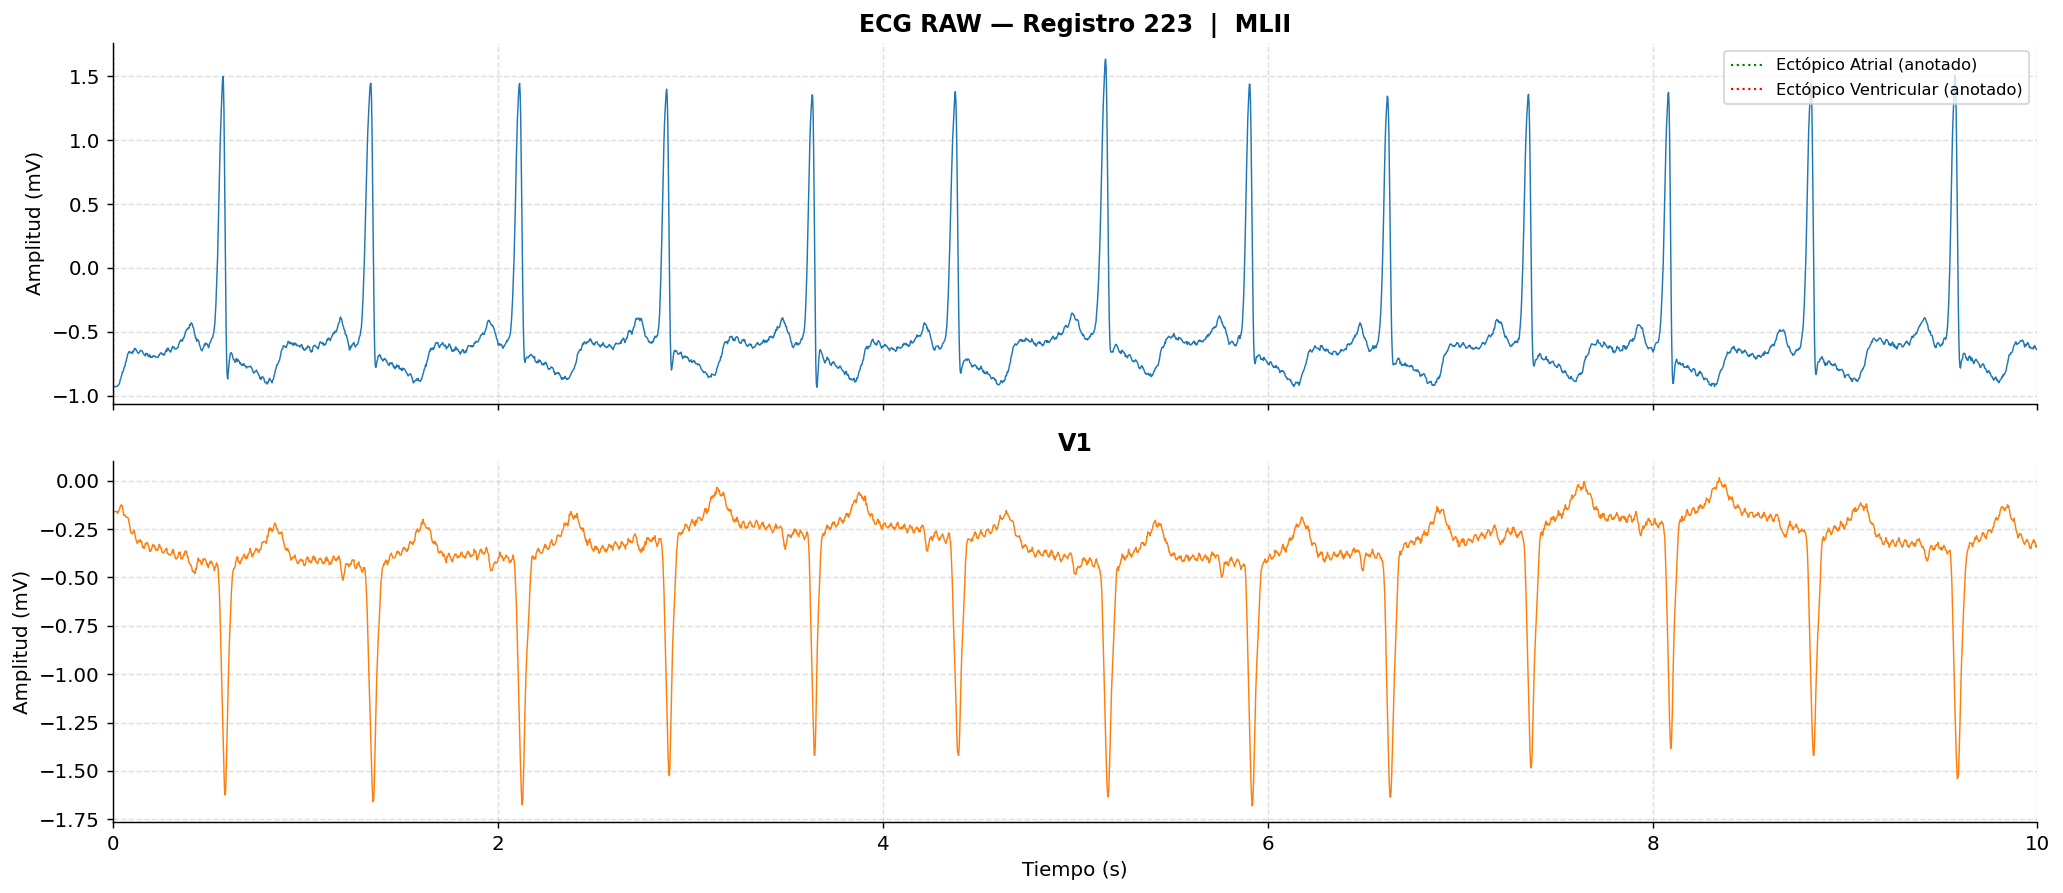

In [4]:
# CELDA 2 - Primer visualización de los registros

# Registros totales del dataset
registros = sorted(set(
    f.split('.')[0]
    for f in os.listdir(DATASET_PATH)
    if f.endswith('.hea')
))
print(f"Registros encontrados: {registros}")
print(f"Cantidad de registros: {len(registros)}")

# Selección del primer registro para su visualización
registro_actual = '223'
record_path = os.path.join(DATASET_PATH, registro_actual)

record  = wfdb.rdrecord(record_path)
annot   = wfdb.rdann(record_path, 'atr')      # Anotaciones oficiales MIT-BIH

fs          = record.fs                       # 360 Hz en MIT-BIH
señal_c0    = record.p_signal[:, 0]           # Canal MLII (principal)
señal_c1    = record.p_signal[:, 1]           # Canal V5  (secundario)
tiempo      = np.arange(len(señal_c0)) / fs

# Anotaciones: posiciones y símbolos de cada latido
ann_samples = annot.sample                     # muestra donde ocurre cada latido
ann_symbols = np.array(annot.symbol)           # símbolo del latido

# Clasificación MIT-BIH de latidos ectópicos
NORMALES   = set('NLRejnBFf')      # Incluye fusiones y marcapasos "normales"
ECTOPICOS_A = set('AaJSe')         # Ectópicos ATRIALES
ECTOPICOS_V = set('VEF')           # Ectópicos VENTRICULARES
TODOS_LATIDOS = NORMALES | ECTOPICOS_A | ECTOPICOS_V

# Filtrar solo anotaciones de latidos (excluir ruido, artefactos, etc.)
mask_latidos   = np.isin(ann_symbols, list(TODOS_LATIDOS))
pos_latidos    = ann_samples[mask_latidos]
sym_latidos    = ann_symbols[mask_latidos]

print("\nDatos del Registro")
print(f"Registro    : {registro_actual}")
print(f"Canal 0     : {record.sig_name[0]}")
print(f"Canal 1     : {record.sig_name[1]}")
print(f"Fs          : {fs} Hz")
print(f"Duración    : {len(señal_c0)/fs:.1f} s")

# Visualización RAW (primeros 10 s, ambos canales)
dur = 10; n = dur * fs
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
ax1.plot(tiempo[:n], señal_c0[:n], color='#1f77b4', lw=0.8)
ax1.set_title(f'ECG RAW — Registro {registro_actual}  |  {record.sig_name[0]}',
              fontweight='bold')
ax1.set_ylabel(f'Amplitud ({record.units[0]})')
ax1.grid(True, ls='--', alpha=0.4); ax1.spines[['top','right']].set_visible(False)

ax2.plot(tiempo[:n], señal_c1[:n], color='#ff7f0e', lw=0.8)
ax2.set_title(f'{record.sig_name[1]}', fontweight='bold')
ax2.set_xlabel('Tiempo (s)'); ax2.set_ylabel(f'Amplitud ({record.units[1]})')
ax2.set_xlim(0, dur)
ax2.grid(True, ls='--', alpha=0.4); ax2.spines[['top','right']].set_visible(False)

# Marcar ectópicos en RAW
for s, label, color in [(ECTOPICOS_A,'Ectópico A','green'),
                         (ECTOPICOS_V,'Ectópico V','red')]:
    mask = np.isin(sym_latidos, list(s)) & (pos_latidos < n)
    for p in pos_latidos[mask]:
        ax1.axvline(p/fs, color=color, alpha=0.5, lw=1.2, ls=':')
        ax2.axvline(p/fs, color=color, alpha=0.5, lw=1.2, ls=':')

ax1.axvline(0, color='green',  lw=1.2, ls=':', label='Ectópico Atrial (anotado)')
ax1.axvline(0, color='red',    lw=1.2, ls=':', label='Ectópico Ventricular (anotado)')
ax1.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.savefig('01_ecg_raw.png', bbox_inches='tight')
plt.show()

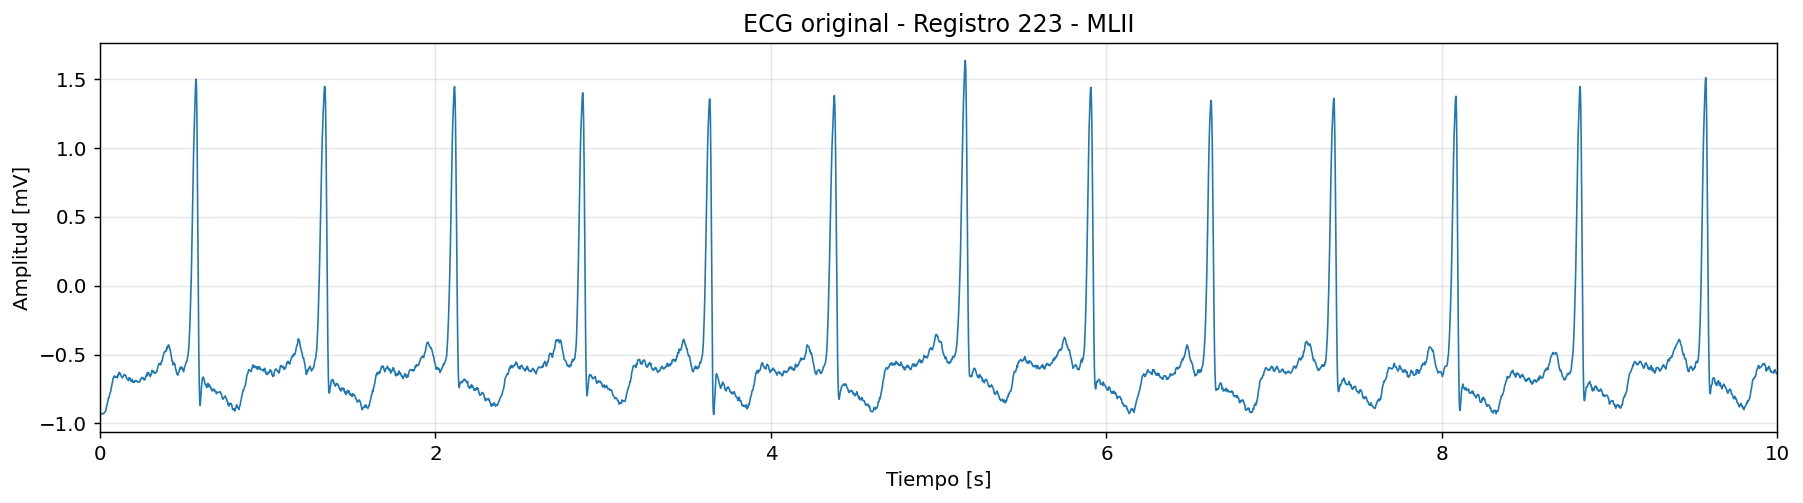

In [5]:
# Visualización inicial del ECG
dur = 10
n = int(dur * fs)

plt.figure(figsize=(14,4))
plt.plot(tiempo[:n], señal_c0[:n], linewidth=0.9)

plt.title(f'ECG original - Registro {registro_actual} - {record.sig_name[0]}')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud [mV]')
plt.xlim(0, dur)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('01_ECG_original.png', dpi=300, bbox_inches='tight')
plt.show()

## Preprocesamiento

Como primer paso se aplican tres filtros en cascada para eliminar los artefactos de los registros:

1. **Pasa-altos Butterworth de orden 2, corte en 0,5 Hz:** elimina la deriva de la línea de base, una variación lenta causada por la respiración, el movimiento o el contacto del electrodo. Se usa 0,5 Hz porque la frecuencia cardíaca mínima fisiológica (30 lpm) equivale a 0,5 Hz, así que no se pierde información del latido.
2. **Pasa-bajos Butterworth de orden 4, corte en 100 Hz:** atenúa el ruido muscular y las interferencias de alta frecuencia. Se eligió un corte alto para no perder las pendientes y muescas del QRS, que después se usan en las características morfológicas.
3. **Notch IIR en 60 Hz, Q = 30:** elimina la interferencia de la red eléctrica (60 Hz en Estados Unidos, donde se grabó la MIT-BIH; el código usa 50 Hz si la frecuencia de muestreo es menor a 250 Hz). Con Q = 30 el notch es muy angosto y solo atenúa la frecuencia de red.

Los filtros se aplican con `filtfilt` (hacia adelante y hacia atrás), que no introduce desfasaje, así las ondas no se corren en el tiempo.

Preprocesamiento completado.
Canal 0 (MLII): HP=0.5Hz | LP=100Hz | Notch=60.0Hz
Canal 1 (V1)  : HP=0.5Hz | LP=100Hz | Notch=60.0Hz


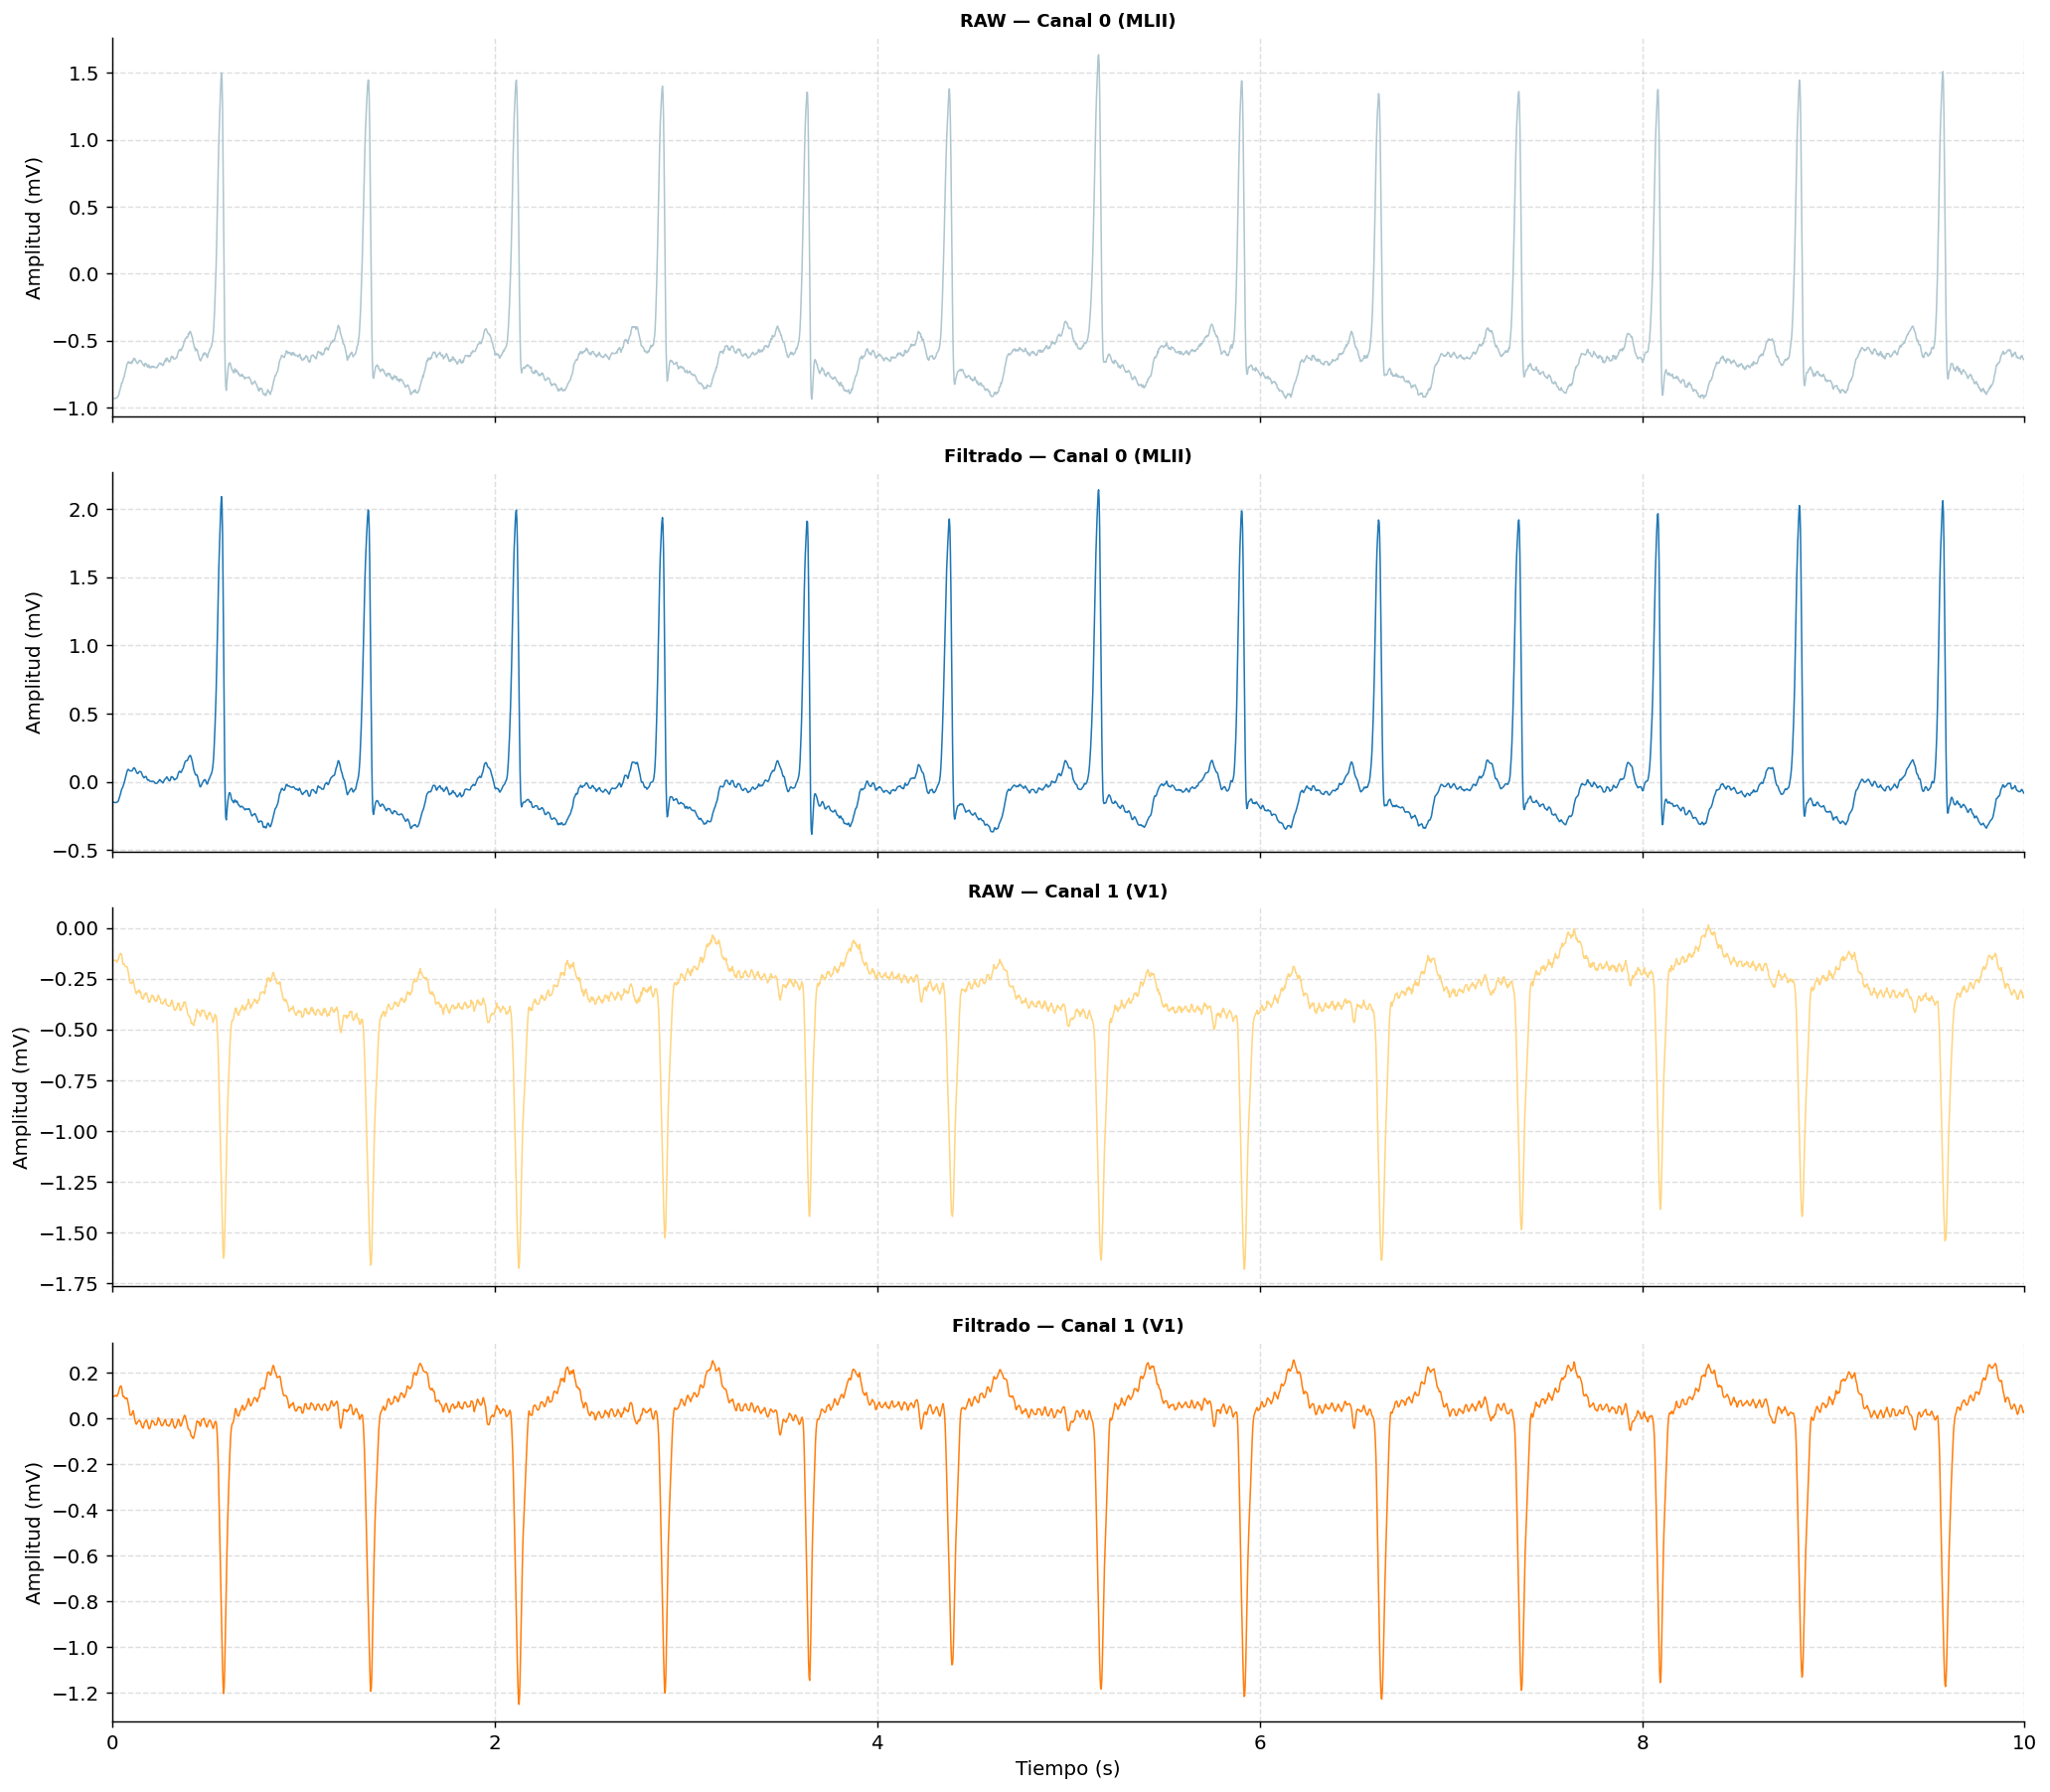

In [6]:
# CELDA 3 - Filtros para los artefactos

def preprocesar_ecg(señal, fs, f_low=0.5, f_high=100.0, f_notch=60.0, Q=30):
    b_hp, a_hp = butter(2, f_low / (fs / 2), btype='high')
    sig = filtfilt(b_hp, a_hp, señal)

    f_high_adj = min(f_high, fs / 2 - 1)
    b_lp, a_lp = butter(4, f_high_adj / (fs / 2), btype='low')
    sig = filtfilt(b_lp, a_lp, sig)

    if f_notch < fs / 2:
        b_n, a_n = iirnotch(f_notch / (fs / 2), Q)
        sig = filtfilt(b_n, a_n, sig)

    return sig

# Detectar frecuencia de red según fs
f_notch = 60.0 if fs >= 250 else 50.0

# Filtrado idéntico e independiente en ambos canales
c0_filt = preprocesar_ecg(señal_c0, fs, f_notch=f_notch)
c1_filt = preprocesar_ecg(señal_c1, fs, f_notch=f_notch)

print(f"Preprocesamiento completado.")
print(f"Canal 0 ({record.sig_name[0]}): HP=0.5Hz | LP=100Hz | Notch={f_notch}Hz")
print(f"Canal 1 ({record.sig_name[1]})  : HP=0.5Hz | LP=100Hz | Notch={f_notch}Hz")

# Visualización: RAW vs Filtrado ────────────────────────────────
dur = 10
n   = dur * fs

datos_vis = [
    (señal_c0[:n], f'RAW — Canal 0 ({record.sig_name[0]})',      '#aec6cf'),
    (c0_filt[:n],  f'Filtrado — Canal 0 ({record.sig_name[0]})', '#1f77b4'),
    (señal_c1[:n], f'RAW — Canal 1 ({record.sig_name[1]})',      '#ffd580'),
    (c1_filt[:n],  f'Filtrado — Canal 1 ({record.sig_name[1]})', '#ff7f0e'),
]

fig, axes = plt.subplots(4, 1, figsize=(16, 14), sharex=True)

for ax, (sig, label, color) in zip(axes, datos_vis):
    ax.plot(tiempo[:n], sig, color=color, lw=0.85)
    ax.set_title(label, fontweight='bold', fontsize=10)
    ax.set_ylabel('Amplitud (mV)')
    ax.grid(True, ls='--', alpha=0.4)
    ax.spines[['top', 'right']].set_visible(False)

axes[-1].set_xlabel('Tiempo (s)')
axes[-1].set_xlim(0, dur)

plt.tight_layout()
plt.savefig('02_preprocesamiento.png', bbox_inches='tight')
plt.show()

## Análisis espectral del ECG mediante PSD

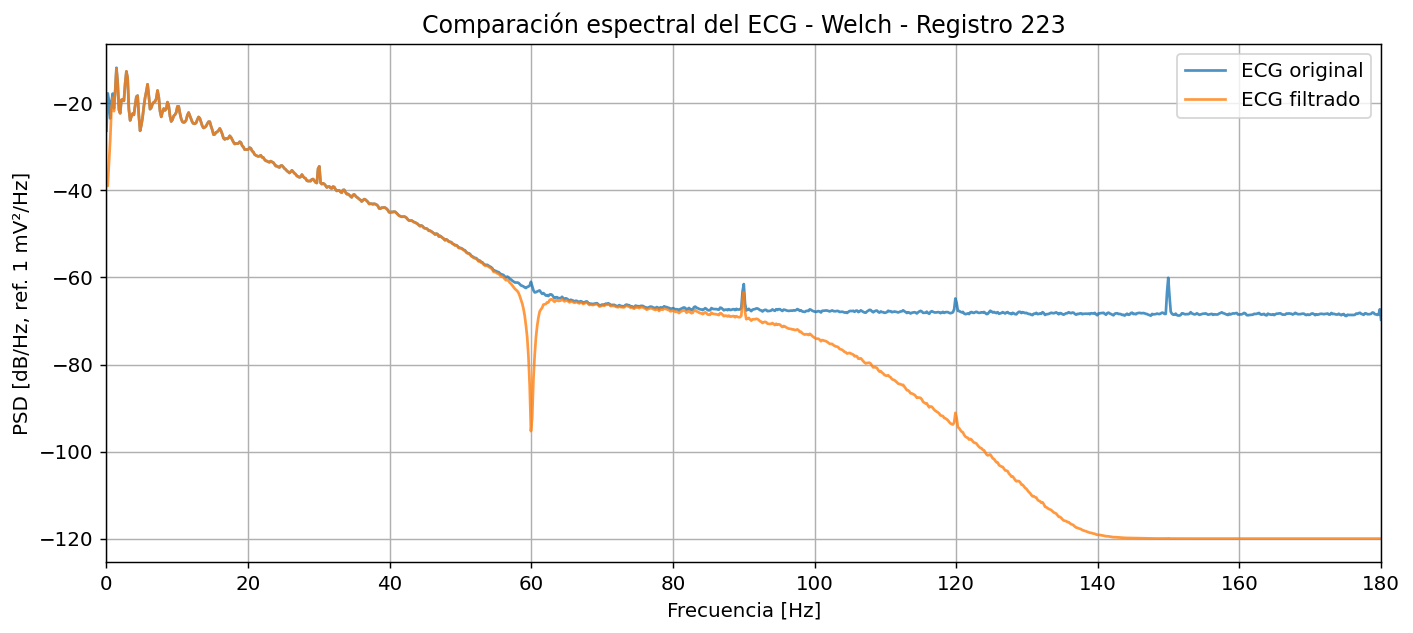

Atenuación en 60 Hz: 34.3 dB


In [7]:
# ==========================================
# ANÁLISIS ESPECTRAL DEL ECG - MÉTODO WELCH
# ==========================================

nperseg = 2048
noverlap = 1024

f_original, psd_original = welch(señal_c0, fs=fs, nperseg=nperseg, noverlap=noverlap)
f_filtrado, psd_filtrado = welch(c0_filt,  fs=fs, nperseg=nperseg, noverlap=noverlap)

eps = 1e-12
plt.figure(figsize=(11, 5))
plt.plot(f_original, 10 * np.log10(psd_original + eps), label='ECG original', alpha=0.8)
plt.plot(f_filtrado, 10 * np.log10(psd_filtrado + eps), label='ECG filtrado', alpha=0.8)
plt.xlim(0, fs / 2)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB/Hz, ref. 1 mV²/Hz]')
plt.title(f'Comparación espectral del ECG - Welch - Registro {registro_actual}')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('02b_psd_welch.png', dpi=300, bbox_inches='tight')
plt.show()

# Atenuación en la frecuencia de red
i60 = np.argmin(np.abs(f_original - f_notch))
print(f"Atenuación en {f_notch:.0f} Hz: "
      f"{10*np.log10(psd_original[i60]/psd_filtrado[i60]):.1f} dB")

Una vez filtradas las señales, los latidos se detectan con el algoritmo de Pan-Tompkins, aplicado sobre cada canal por separado. Después se combinan las detecciones de los dos canales.

Pasos de Pan-Tompkins:

1. **Pasa-banda de 5 a 15 Hz:** deja pasar la banda donde está la energía del QRS. Las ondas P y T quedan por debajo de 5 Hz y el ruido muscular por encima de 15 Hz.
2. **Derivada de 5 puntos:** resalta los cambios rápidos de pendiente. El QRS es la parte del ECG con la pendiente más pronunciada.
3. **Elevación al cuadrado:** hace toda la señal positiva (el QRS puede ser positivo o negativo según la derivación) y agranda los valores altos frente a los bajos.
4. **Integración con una ventana móvil de 150 ms:** convierte cada QRS en una "loma" suave. Se usan 150 ms porque es aproximadamente la duración máxima de un QRS.
5. **Umbral adaptativo:** se buscan picos separados al menos 200 ms. Si un pico supera el umbral, se toma como QRS y actualiza el nivel de señal (SPK); si no, actualiza el nivel de ruido (NPK). El umbral se recalcula como NPK + 0,25·(SPK − NPK), así se adapta a los cambios de amplitud a lo largo del registro.

Funciones adicionales:

1. **`ajuste_fino_picos`:** la integración corre un poco el pico respecto del R real. Esta función busca el máximo de la señal filtrada en ±50 ms alrededor de cada detección y reubica el pico ahí.
2. **`refractario_dinamico`:** elimina detecciones duplicadas demasiado cercanas. El período refractario es una fracción del RR estimado (inicialmente el 75 %, entre 200 y 500 ms), así se adapta a la frecuencia cardíaca.
3. **`calidad_local`:** mide cuánto se destaca un pico de su entorno, como el cociente entre el pico y la mediana de la señal integrada en ±300 ms. Si es mayor a 2,5, probablemente es un QRS real.
4. **`fusionar_and_or`:** combina los dos canales.
    - *AND:* si los dos canales detectan un pico a menos de 80 ms, es el mismo latido y se acepta. Se conserva la posición de MLII, porque las anotaciones están marcadas sobre esa derivación.
    - *OR:* si lo detecta un solo canal, se acepta solo si su calidad local es mayor a 2,5. Así se recuperan latidos que un canal no vio por ruido, sin aceptar cualquier pico.

Al final se ordenan los picos y se vuelve a aplicar el periodo refractario para eliminar los duplicados.
  

Pan-Tompkins adaptativo
Picos Canal 0 (raw)   : 2514
Picos Canal 1 (raw)   : 2500
Picos fusionados      : 2451
Picos referencia      : 2605
Diferencia vs ref     : -154
FC media estimada     : 81.4 lpm


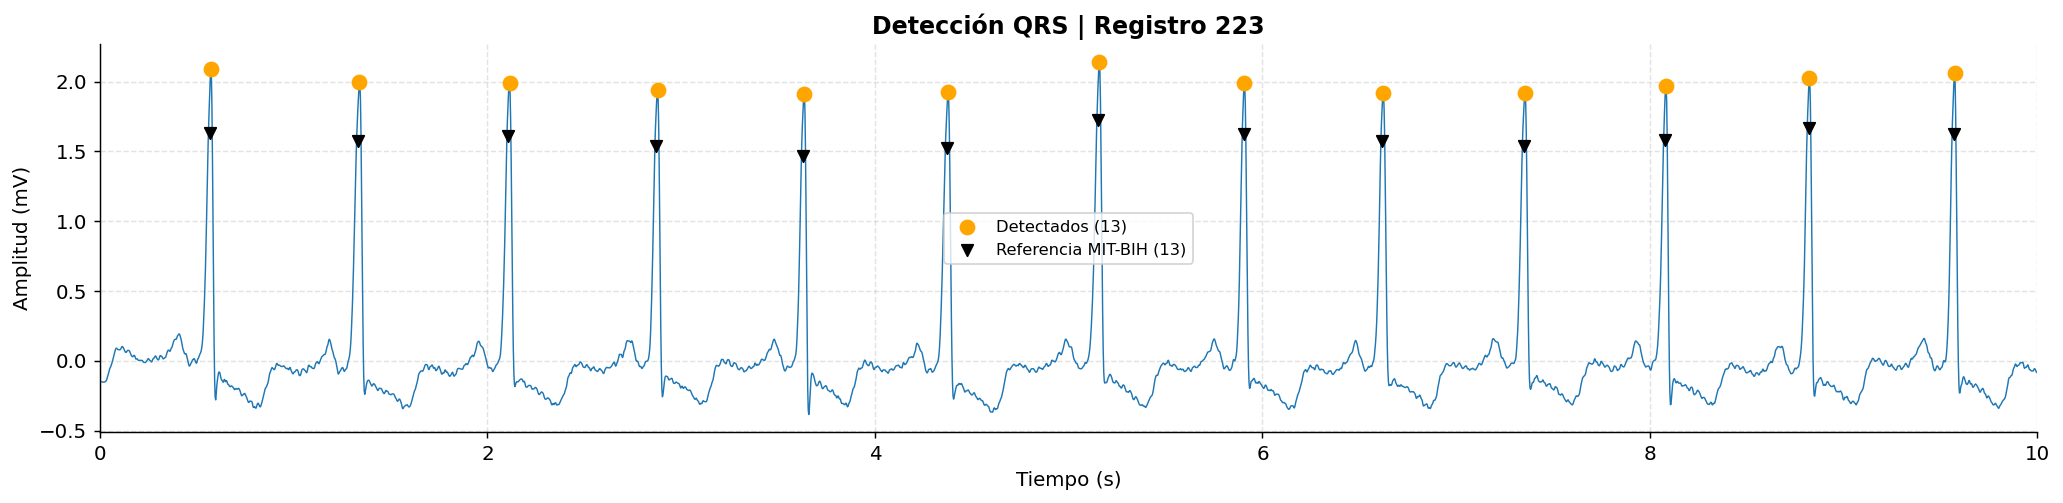

In [8]:
# CELDA 4 — Pan-Tompkins

def pan_tompkins_single(señal, fs):
    """
    Pan-Tompkins sobre un canal. Retorna picos R y la señal
    integrada (para estimar calidad local de detección).
    """
    # 1. Pasa-banda 5–15 Hz
    b_hp, a_hp = butter(2,  5.0 / (fs / 2), btype='high')
    b_lp, a_lp = butter(2, 15.0 / (fs / 2), btype='low')
    sig = filtfilt(b_hp, a_hp, señal)
    sig = filtfilt(b_lp, a_lp, sig)

    # 2. Derivada de 5 puntos
    h     = np.array([-1, -2, 0, 2, 1]) * (fs / 8)
    deriv = np.convolve(sig, h, mode='same')

    # 3. Cuadrado
    squared = deriv ** 2

    # 4. Ventana móvil 150 ms
    N_win  = int(0.150 * fs)
    integ  = np.convolve(squared, np.ones(N_win) / N_win, mode='same')

    # 5. Umbralización adaptativa
    init_win = min(int(2 * fs), len(integ))
    SPK = 0.5 * np.max(integ[:init_win])
    NPK = 0.0
    threshold = SPK
    min_dist_init = int(0.200 * fs)

    candidatos, _ = find_peaks(integ, distance=min_dist_init,
                                height=0.15 * np.max(integ[:init_win]))
    picos = []
    for p in candidatos:
        if integ[p] >= threshold:
            picos.append(p)
            SPK = 0.125 * integ[p] + 0.875 * SPK
        else:
            NPK = 0.125 * integ[p] + 0.875 * NPK
        threshold = NPK + 0.25 * (SPK - NPK)

    return np.array(picos, dtype=int), integ


def ajuste_fino_picos(picos_raw, señal_filtrada, fs, half_win_ms=50):
    """
    Reposiciona cada pico al máximo absoluto de la señal filtrada
    dentro de una ventana ±half_win_ms alrededor del candidato.
    """
    hw = int(half_win_ms * fs / 1000)
    ajustados = []
    for p in picos_raw:
        ini = max(0, p - hw)
        fin = min(len(señal_filtrada), p + hw)
        p_aj = ini + np.argmax(np.abs(señal_filtrada[ini:fin]))
        ajustados.append(int(p_aj))
    return np.array(ajustados, dtype=int)


def refractario_dinamico(picos, fs, fraccion=0.75, min_ms=200, max_ms=500):
    """
    Elimina picos demasiado cercanos usando un período refractario
    dinámico = fraccion × RR_medio_local.
    Esto se adapta a taquicardias y bradicardias.
    """
    if len(picos) == 0:
        return picos

    min_samp = int(min_ms * fs / 1000)
    max_samp = int(max_ms * fs / 1000)

    filtrados = [picos[0]]
    rr_estimado = int(0.800 * fs)   # inicialización 75 lpm

    for p in picos[1:]:
        refrac = int(np.clip(fraccion * rr_estimado, min_samp, max_samp))
        if p - filtrados[-1] >= refrac:
            rr_estimado = int(0.875 * rr_estimado + 0.125 * (p - filtrados[-1]))
            filtrados.append(p)

    return np.array(filtrados, dtype=int)


def calidad_local(integ, pico, fs, ventana_ms=300):
    """
    SNR local estimado como ratio entre el valor del pico
    y la mediana de la señal integrada en ventana alrededor del pico.
    Retorna valor > 1 si el pico es prominente localmente.
    """
    hw = int(ventana_ms * fs / 1000)
    ini = max(0, pico - hw)
    fin = min(len(integ), pico + hw)
    entorno = np.median(integ[ini:fin])
    if entorno < 1e-12:
        return 10.0
    return float(integ[pico] / (entorno + 1e-12))


def fusionar_and_or(picos_c0, picos_c1, integ_c0, integ_c1, fs,
                     ventana_ms=80, umbral_calidad=2.5):
    """
    Fusión AND/OR adaptativa:
    · AND: pico detectado en ambos canales dentro de ventana_ms → posición de MLII
    · OR:  pico detectado en un solo canal, solo si su calidad local
           supera umbral_calidad (el pico es prominente respecto al ruido)
    Esto reduce FP respecto al OR puro sin aumentar FN en señales limpias.
    """
    tol      = int(ventana_ms * fs / 1000)
    usados1  = np.zeros(len(picos_c1), dtype=bool)
    fusionados = []
    calidades  = []

    for p0 in picos_c0:
        if len(picos_c1) == 0:
            q = calidad_local(integ_c0, p0, fs)
            if q >= umbral_calidad:
                fusionados.append(p0)
                calidades.append(q)
            continue

        dists = np.abs(picos_c1 - p0)
        j     = np.argmin(dists)

        if dists[j] <= tol and not usados1[j]:
            # AND: confirmado por ambos canales → se conserva la posición de MLII
            fusionados.append(int(p0))
            calidades.append(99.0)   # máxima confianza
            usados1[j] = True
        else:
            # Solo C0: aceptar solo si calidad es suficiente
            q = calidad_local(integ_c0, p0, fs)
            if q >= umbral_calidad:
                fusionados.append(p0)
                calidades.append(q)

    # Picos de C1 no emparejados
    for j, p1 in enumerate(picos_c1):
        if not usados1[j]:
            q = calidad_local(integ_c1, p1, fs)
            if q >= umbral_calidad:
                fusionados.append(p1)
                calidades.append(q)

    if len(fusionados) == 0:
        return np.array([], dtype=int)

    # Ordenar por posición
    orden      = np.argsort(fusionados)
    fusionados = np.array(fusionados, dtype=int)[orden]

    # Período refractario dinámico final
    fusionados = refractario_dinamico(fusionados, fs)

    return fusionados


# Ejecutar ──────────────────────────────────────────────────────
picos_raw_c0, integ_c0 = pan_tompkins_single(c0_filt, fs)
picos_raw_c1, integ_c1 = pan_tompkins_single(c1_filt, fs)

# Ajuste fino sobre señal filtrada
picos_aj_c0 = ajuste_fino_picos(picos_raw_c0, c0_filt, fs)
picos_aj_c1 = ajuste_fino_picos(picos_raw_c1, c1_filt, fs)

# Fusión AND/OR
picos_r = fusionar_and_or(picos_aj_c0, picos_aj_c1, integ_c0, integ_c1, fs)

print(f"Pan-Tompkins adaptativo")
print(f"Picos Canal 0 (raw)   : {len(picos_raw_c0)}")
print(f"Picos Canal 1 (raw)   : {len(picos_raw_c1)}")
print(f"Picos fusionados      : {len(picos_r)}")
print(f"Picos referencia      : {len(pos_latidos)}")
print(f"Diferencia vs ref     : {len(picos_r) - len(pos_latidos):+d}")
print(f"FC media estimada     : {len(picos_r)/(len(señal_c0)/fs)*60:.1f} lpm")

# Visualización
dur2 = 10; n2 = dur2 * fs
picos_10 = picos_r[picos_r < n2]
ref_10   = pos_latidos[pos_latidos < n2]

fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(tiempo[:n2], c0_filt[:n2], color='#1f77b4', lw=0.8)
ax.scatter(picos_10 / fs, c0_filt[picos_10],
           color='orange', s=60, zorder=5,
           label=f'Detectados ({len(picos_10)})')
ax.scatter(ref_10 / fs, c0_filt[ref_10] - 0.3,
           color='black', marker='v', s=40, zorder=6,
           label=f'Referencia MIT-BIH ({len(ref_10)})')
ax.set_title(f'Detección QRS | Registro {registro_actual}',
             fontweight='bold')
ax.set_xlabel('Tiempo (s)'); ax.set_ylabel('Amplitud (mV)')
ax.set_xlim(0, dur2); ax.legend(fontsize=9)
ax.grid(True, ls='--', alpha=0.35)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('03_picos_fusionados.png', bbox_inches='tight')
plt.show()

## Validación de la detección de complejos QRS

Para evaluar el desempeño de la detección, se comparan las posiciones de los picos R detectados con las anotaciones de referencia de la MIT-BIH Arrhythmia Database.

**1. Emparejamiento con la referencia**

Para cada anotación de referencia se buscan las detecciones ubicadas dentro de una tolerancia de ±150 ms. Las asociaciones se ordenan por error temporal y se asignan de menor a mayor error, de forma que cada detección y cada anotación se emparejan como máximo una vez. Este criterio de 150 ms es el estándar de la literatura para MIT-BIH.

De ese proceso salen tres categorías:

- **TP:** picos detectados que tienen una referencia cercana dentro de la tolerancia.
- **FP:** picos detectados que no tienen ninguna referencia cercana (latidos inventados).
- **FN:** referencias que no fueron detectadas por ningún pico (latidos perdidos).

**2. Métricas de detección QRS**

*Sensibilidad (Se):* fracción de los latidos reales que fue detectada. Un valor bajo significa que se pierden latidos.

$$Se = \frac{TP}{TP + FN}$$

*Precisión o valor predictivo positivo (Pp):* fracción de las detecciones que corresponde a latidos reales. Un valor bajo significa muchas falsas alarmas.

$$Pp = \frac{TP}{TP + FP}$$

*F1-Score:* media armónica de sensibilidad y precisión. Penaliza fuertemente si cualquiera de las dos es baja.

$$F1 = \frac{2 \cdot Se \cdot Pp}{Se + Pp}$$

Adicionalmente se calcula el error de posición en milisegundos para cada par TP. Se reportan la media y la mediana; la mediana es más robusta porque no se ve afectada por errores grandes aislados.

**3. Análisis de los latidos perdidos por clase**

Como el objetivo del trabajo es clasificar latidos ectópicos, además de las métricas globales se analiza a qué clase pertenecen los latidos no detectados (FN). Una pérdida concentrada en una clase indica un sesgo del detector que afectaría directamente a la clasificación posterior.

Validación de la detección QRS — Registro 223
   TP                  : 2451
   FP                  : 0
   FN                  : 154
   Se                  : 0.9409
   Pp                  : 1.0000
   F1                  : 0.9695
   Error medio (ms)    : 5.6859
   Error mediano (ms)  : 5.5556

Latidos no detectados por clase:


,Anotados,No detectados (FN),% perdido
N,2029,1,0.0
V,473,148,31.3
A,72,5,6.9
e,16,0,0.0
F,14,0,0.0
a,1,0,0.0


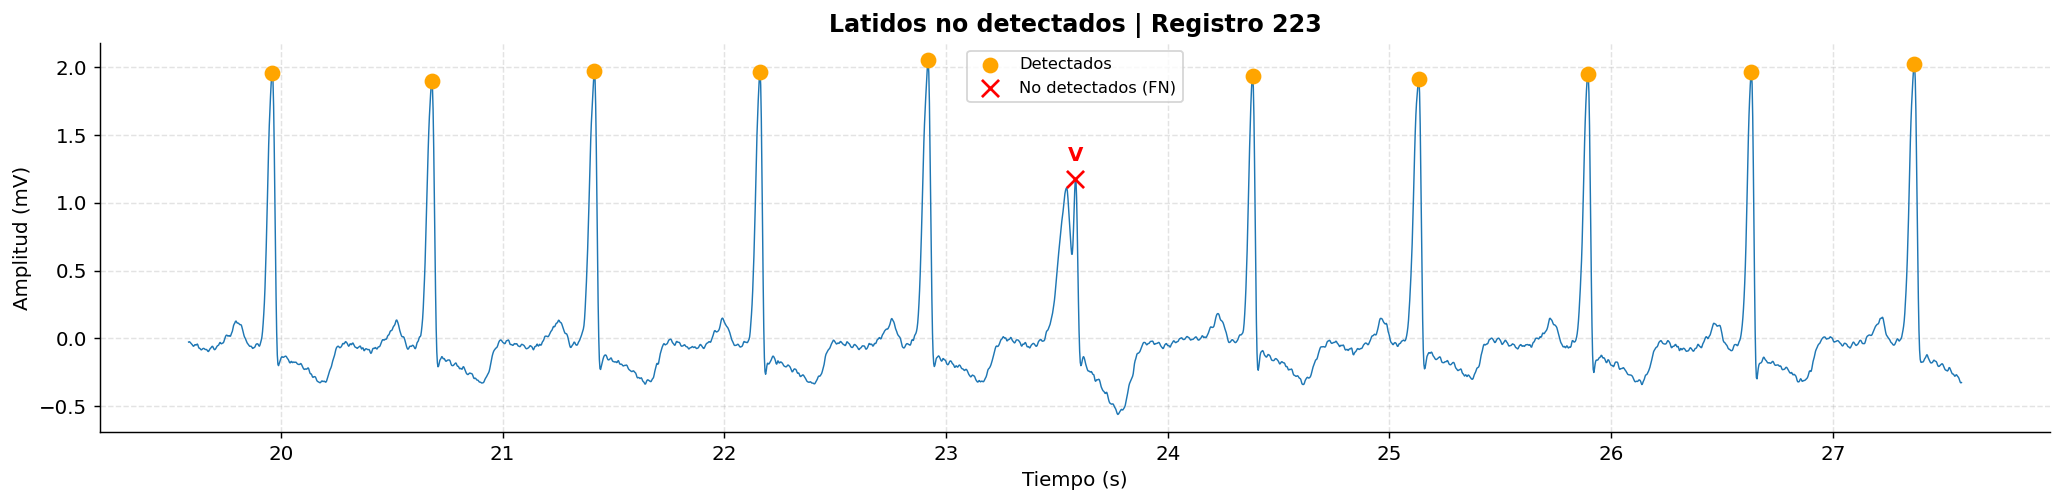

In [9]:
# CELDA 5 - Validación de la detección QRS

def match_detecciones_referencia(det_peaks, ref_peaks, fs, tolerancia_ms=150):
    """
    Asociación uno a uno entre detecciones y referencias, priorizando
    el menor error temporal. Devuelve:
      · ref_de_det: índice de la referencia asociada a cada detección (-1 = FP)
      · ref_usada : True si la referencia fue detectada (False = FN)
    """
    det_peaks = np.sort(np.asarray(det_peaks, dtype=int))
    tol = int(tolerancia_ms * fs / 1000)
    pares = []
    for i, ref in enumerate(ref_peaks):
        j0 = np.searchsorted(det_peaks, ref - tol, side='left')
        j1 = np.searchsorted(det_peaks, ref + tol, side='right')
        for j in range(j0, j1):
            pares.append((abs(det_peaks[j] - ref), i, j))
    pares.sort()

    ref_de_det = -np.ones(len(det_peaks), dtype=int)
    ref_usada  = np.zeros(len(ref_peaks), dtype=bool)
    for err, i, j in pares:
        if not ref_usada[i] and ref_de_det[j] == -1:
            ref_usada[i]  = True
            ref_de_det[j] = i
    return ref_de_det, ref_usada


def metricas_deteccion(det_peaks, ref_peaks, fs, tolerancia_ms=150):
    det_peaks = np.sort(np.asarray(det_peaks, dtype=int))
    ref_de_det, ref_usada = match_detecciones_referencia(det_peaks, ref_peaks, fs, tolerancia_ms)
    TP = int(ref_usada.sum())
    FP = len(det_peaks) - TP
    FN = len(ref_peaks) - TP
    Se = TP / max(TP + FN, 1)
    Pp = TP / max(TP + FP, 1)
    F1 = 2 * Se * Pp / max(Se + Pp, 1e-12)
    m = ref_de_det >= 0
    err_ms = np.abs(det_peaks[m] - ref_peaks[ref_de_det[m]]) / fs * 1000
    return {'TP': TP, 'FP': FP, 'FN': FN, 'Se': Se, 'Pp': Pp, 'F1': F1,
            'Error medio (ms)': float(np.mean(err_ms)) if len(err_ms) else np.nan,
            'Error mediano (ms)': float(np.median(err_ms)) if len(err_ms) else np.nan}, ref_usada


# Ejecutar ──────────────────────────────────────────────────────
met, ref_usada = metricas_deteccion(picos_r, pos_latidos, fs)

print(f"Validación de la detección QRS — Registro {registro_actual}")
for k, v in met.items():
    print(f"   {k:<20}: {v:.4f}" if isinstance(v, float) else f"   {k:<20}: {v}")

# ¿Qué latidos se pierden? (FN por símbolo MIT-BIH)
fn_sym = pd.Series(sym_latidos[~ref_usada]).value_counts()
tot_sym = pd.Series(sym_latidos).value_counts()
tabla_fn = pd.DataFrame({'Anotados': tot_sym, 'No detectados (FN)': fn_sym}).fillna(0).astype(int)
tabla_fn['% perdido'] = (100 * tabla_fn['No detectados (FN)'] / tabla_fn['Anotados']).round(1)
print("\nLatidos no detectados por clase:")
display(tabla_fn.sort_values('Anotados', ascending=False))

# Visualización de un tramo con latidos perdidos
fn_pos = pos_latidos[~ref_usada]
if len(fn_pos):
    centro = fn_pos[0]
    i0 = max(0, centro - 4 * fs); i1 = min(len(c0_filt), centro + 4 * fs)
    t = np.arange(i0, i1) / fs
    det_v = picos_r[(picos_r >= i0) & (picos_r < i1)]
    fn_v  = fn_pos[(fn_pos >= i0) & (fn_pos < i1)]

    fig, ax = plt.subplots(figsize=(16, 4))
    ax.plot(t, c0_filt[i0:i1], color='#1f77b4', lw=0.8)
    ax.scatter(det_v / fs, c0_filt[det_v], color='orange', s=60, zorder=5, label='Detectados')
    ax.scatter(fn_v / fs, c0_filt[fn_v], color='red', marker='x', s=90, zorder=6,
               label='No detectados (FN)')
    for p in fn_v:
        s = sym_latidos[pos_latidos == p][0]
        ax.annotate(s, (p / fs, c0_filt[p]), textcoords='offset points', xytext=(0, 10),
                    ha='center', color='red', fontweight='bold')
    ax.set_title(f'Latidos no detectados | Registro {registro_actual}', fontweight='bold')
    ax.set_xlabel('Tiempo (s)'); ax.set_ylabel('Amplitud (mV)')
    ax.legend(fontsize=9); ax.grid(True, ls='--', alpha=0.35)
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.savefig('03b_latidos_perdidos.png', bbox_inches='tight')
    plt.show()

## Ajuste del período refractario

El período refractario dinámico original (75 % del RR local, entre 200 y 500 ms) elimina cualquier detección que ocurra antes del 75 % del intervalo RR esperado. Sin embargo, los latidos ectópicos son, por definición, prematuros: un PVC o un PAC suele ocurrir al 50–70 % del RR normal. Con ese criterio, el detector descarta justamente los latidos que se busca clasificar.

Por este motivo se redujo el período refractario al 40 % del RR local, con un mínimo de 200 ms y un máximo de 300 ms. El límite superior de 300 ms se basa en el período refractario fisiológico ventricular: un latido ectópico puede producirse ya a partir de ~300 ms del latido anterior, por lo que el refractario no debe superar ese valor. El mínimo de 200 ms sigue evitando la doble detección de un mismo complejo QRS.

In [10]:
# CELDA 6 - Ajuste del período refractario y nueva validación

# Parámetros del refractario (se leen en cada llamada)
REFRACTARIO = {'fraccion': 0.75, 'min_ms': 200, 'max_ms': 500}

def refractario_dinamico(picos, fs, fraccion=None, min_ms=None, max_ms=None):
    """
    Período refractario dinámico = fraccion × RR_medio_local,
    limitado entre min_ms y max_ms.
    """
    fraccion = REFRACTARIO['fraccion'] if fraccion is None else fraccion
    min_ms   = REFRACTARIO['min_ms']   if min_ms   is None else min_ms
    max_ms   = REFRACTARIO['max_ms']   if max_ms   is None else max_ms

    if len(picos) == 0:
        return picos

    min_samp = int(min_ms * fs / 1000)
    max_samp = int(max_ms * fs / 1000)

    filtrados = [picos[0]]
    rr_estimado = int(0.800 * fs)   # inicialización 75 lpm

    for p in picos[1:]:
        refrac = int(np.clip(fraccion * rr_estimado, min_samp, max_samp))
        if p - filtrados[-1] >= refrac:
            rr_estimado = int(0.875 * rr_estimado + 0.125 * (p - filtrados[-1]))
            filtrados.append(p)

    return np.array(filtrados, dtype=int)


# 1) Refractario original: 75 % del RR, entre 200 y 500 ms
REFRACTARIO.update(fraccion=0.75, min_ms=200, max_ms=500)
picos_orig = fusionar_and_or(picos_aj_c0, picos_aj_c1, integ_c0, integ_c1, fs)
met_antes, ref_usada_antes = metricas_deteccion(picos_orig, pos_latidos, fs)

# 2) Refractario ajustado: 40 % del RR, entre 200 y 300 ms
REFRACTARIO.update(fraccion=0.40, min_ms=200, max_ms=300)
picos_r = fusionar_and_or(picos_aj_c0, picos_aj_c1, integ_c0, integ_c1, fs)
met, ref_usada = metricas_deteccion(picos_r, pos_latidos, fs)

comparacion = pd.DataFrame({'Refractario original (75 %)': met_antes,
                            'Refractario ajustado (40 %)': met}).T
display(comparacion.round(4))

# Latidos perdidos por clase, antes y después
tabla_fn = pd.DataFrame({
    'Anotados'    : pd.Series(sym_latidos).value_counts(),
    'FN original' : pd.Series(sym_latidos[~ref_usada_antes]).value_counts(),
    'FN ajustado' : pd.Series(sym_latidos[~ref_usada]).value_counts(),
}).fillna(0).astype(int).sort_values('Anotados', ascending=False)
display(tabla_fn)

,TP,FP,FN,Se,Pp,F1,Error medio (ms),Error mediano (ms)
Refractario original (75 %),2451.0,0.0,154.0,0.9409,1.0,0.9695,5.6859,5.5556
Refractario ajustado (40 %),2570.0,0.0,35.0,0.9866,1.0,0.9932,5.5556,5.5556


,Anotados,FN original,FN ajustado
N,2029,1,1
V,473,148,34
A,72,5,0
e,16,0,0
F,14,0,0
a,1,0,0


In [11]:
# CELDA 7 - Diagnóstico de los latidos que siguen sin detectarse

tol = int(0.150 * fs)
fn_pos = pos_latidos[~ref_usada]
fn_sym = sym_latidos[~ref_usada]

def detectado_en(picos, p):
    return bool(np.any(np.abs(picos - p) <= tol))

df_fn = pd.DataFrame({
    'muestra'          : fn_pos,
    'tiempo (s)'       : np.round(fn_pos / fs, 2),
    'símbolo'          : fn_sym,
    'ms desde R previo': [round((p - picos_r[picos_r < p].max()) / fs * 1000)
                          if np.any(picos_r < p) else np.nan for p in fn_pos],
    'visto en MLII'    : [detectado_en(picos_aj_c0, p) for p in fn_pos],
    'visto en canal 2' : [detectado_en(picos_aj_c1, p) for p in fn_pos],
})
display(df_fn)

print("Resumen:")
print(f"   No vistos por ningún canal (falla Pan-Tompkins): "
      f"{(~df_fn['visto en MLII'] & ~df_fn['visto en canal 2']).sum()}")
print(f"   Vistos por algún canal pero eliminados (fusión/refractario): "
      f"{(df_fn['visto en MLII'] | df_fn['visto en canal 2']).sum()}")

,muestra,tiempo (s),símbolo,ms desde R previo,visto en MLII,visto en canal 2
0,8490,23.58,V,664,False,False
1,22251,61.81,V,594,False,False
2,49943,138.73,V,689,False,False
3,67740,188.17,V,611,False,False
4,101044,280.68,V,675,False,False
5,154491,429.14,V,617,False,False
6,229559,637.66,N,642,False,False
7,239974,666.59,V,625,False,False
8,323522,898.67,V,753,False,False
9,365119,1014.22,V,728,False,False


Resumen:
   No vistos por ningún canal (falla Pan-Tompkins): 35
   Vistos por algún canal pero eliminados (fusión/refractario): 0


## Composición de la base de datos

Una vez ajustada la detección sobre el registro 223, se define qué registros se utilizan y cómo se dividen para el análisis y la clasificación.

**1. Exclusión de registros con marcapasos**

Se excluyen los registros 102, 104, 107 y 217, siguiendo la recomendación de la norma ANSI/AAMI EC57.

**2. División inter-paciente DS1 / DS2**

Los 44 registros restantes se dividen en dos conjuntos de 22 registros cada uno, según la división propuesta por de Chazal et al. (2004). Todo lo que se ajusta con datos se calcula sobre DS1, y DS2 se utiliza únicamente para la evaluación final. De esta forma, ningún paciente aparece en ambos conjuntos.

**3. Clases**

Se consideran los latidos anotados como normales (N), contracciones auriculares prematuras (A) y contracciones ventriculares prematuras (V). Los demás tipos de latido (bloqueos de rama, fusiones, escapes) se detectan y se usan para calcular los intervalos RR, pero no se incluyen en el análisis de clases.

,Registros,Normal (N),PAC (A),PVC (V),Total N/A/V
Subconjunto,,,,,
DS1 (entrenamiento),22,38102,810,3683,42595
DS2 (prueba),22,36444,1736,3220,41400
Excluido (marcapasos),4,506,0,227,733
Total,48,75052,2546,7130,84728


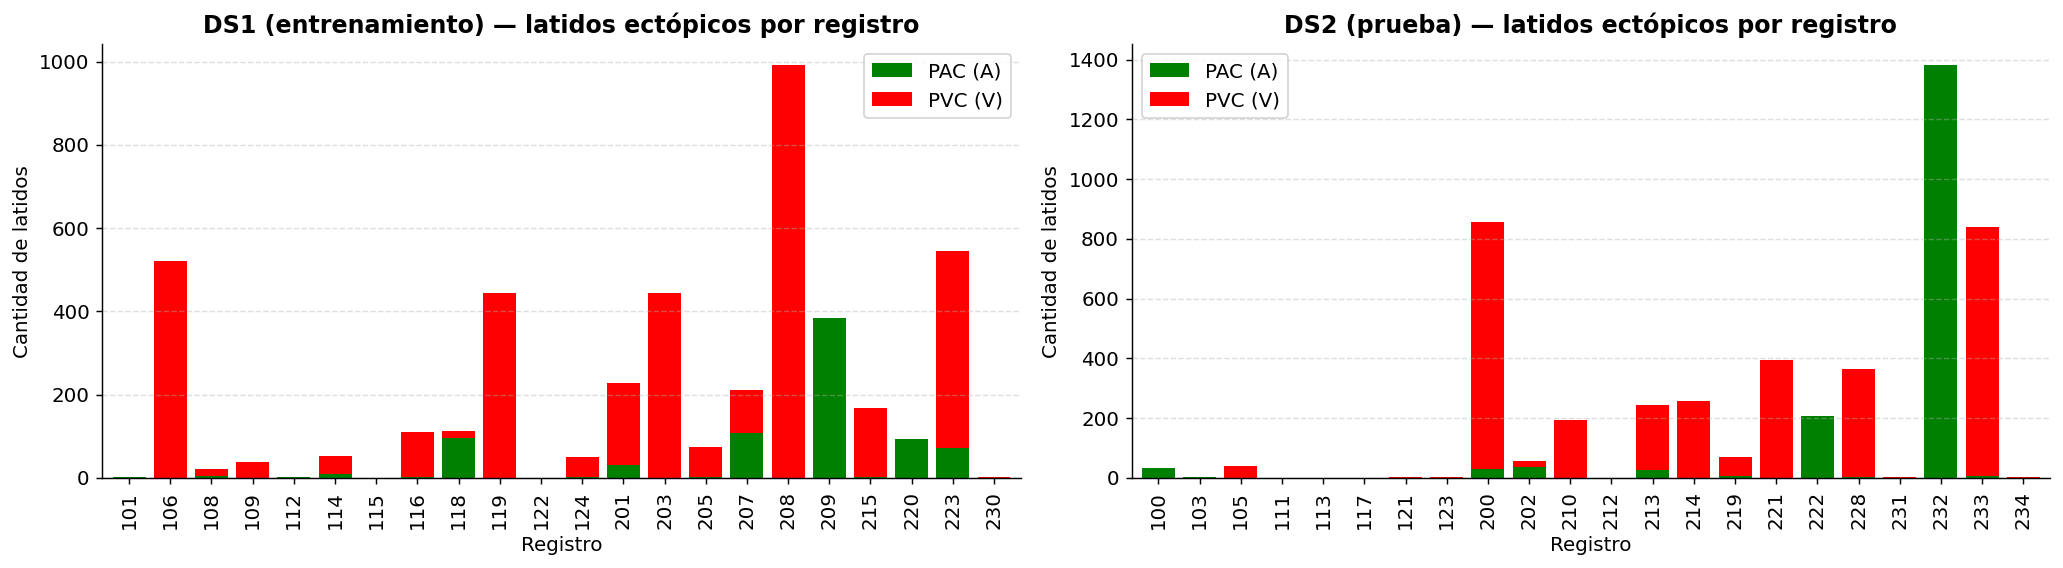

In [12]:
# CELDA 8 - Composición de la base de datos

REG_MARCAPASOS = ['102', '104', '107', '217']

# División inter-paciente de de Chazal et al. (2004)
DS1 = ['101', '106', '108', '109', '112', '114', '115', '116', '118', '119', '122',
       '124', '201', '203', '205', '207', '208', '209', '215', '220', '223', '230']
DS2 = ['100', '103', '105', '111', '113', '117', '121', '123', '200', '202', '210',
       '212', '213', '214', '219', '221', '222', '228', '231', '232', '233', '234']

# Todos los símbolos de MIT-BIH que corresponden a un latido
SIMBOLOS_LATIDO = set('NLRBAaJSVrFejnE/fQ')

def subconjunto(reg):
    if reg in REG_MARCAPASOS:
        return 'Excluido (marcapasos)'
    return 'DS1 (entrenamiento)' if reg in DS1 else 'DS2 (prueba)'

# Conteo de clases por registro a partir de las anotaciones
filas = []
for reg in registros:
    ann = wfdb.rdann(os.path.join(DATASET_PATH, reg), 'atr')
    conteo = pd.Series(ann.symbol).value_counts()
    filas.append({'Registro': reg,
                  'Normal (N)': conteo.get('N', 0),
                  'PAC (A)':    conteo.get('A', 0),
                  'PVC (V)':    conteo.get('V', 0),
                  'Subconjunto': subconjunto(reg)})
df_registros = pd.DataFrame(filas)
df_registros['Total N/A/V'] = df_registros[['Normal (N)', 'PAC (A)', 'PVC (V)']].sum(axis=1)

# Resumen por subconjunto
tabla_ds = df_registros.groupby('Subconjunto')[
    ['Normal (N)', 'PAC (A)', 'PVC (V)', 'Total N/A/V']].sum()
tabla_ds.insert(0, 'Registros', df_registros.groupby('Subconjunto').size())
tabla_ds.loc['Total'] = tabla_ds.sum()
display(tabla_ds)

# Figura: ectópicos por registro en DS1 y DS2
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for k, ds in enumerate(['DS1 (entrenamiento)', 'DS2 (prueba)']):
    sub = df_registros[df_registros['Subconjunto'] == ds].set_index('Registro')
    sub[['PAC (A)', 'PVC (V)']].plot(kind='bar', stacked=True, ax=ax[k],
                                    color=['green', 'red'], width=0.8)
    ax[k].set_title(f'{ds} — latidos ectópicos por registro', fontweight='bold')
    ax[k].set_xlabel('Registro'); ax[k].set_ylabel('Cantidad de latidos')
    ax[k].grid(axis='y', ls='--', alpha=0.4)
    ax[k].spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('05_composicion_DS.png', bbox_inches='tight')
plt.show()

# Detección de complejos QRS en toda la base

Se aplica a los 44 registros el mismo procedimiento ajustado sobre el registro 223.

Como canal principal se toma siempre la derivación MLII, seleccionada por nombre y no por posición, ya que en algunos registros (por ejemplo, el 114) los canales están invertidos.

La detección se valida en cada registro contra todas las anotaciones de latido de MIT-BIH, con una tolerancia de ±150 ms. Además de las métricas por registro se calculan las métricas globales, sumando TP, FP y FN de todos los registros, y la proporción de latidos perdidos por clase.

In [13]:
# CELDA 9 - Detección QRS en toda la base

REFRACTARIO.update(fraccion=0.40, min_ms=200, max_ms=300)   # refractario ajustado

def detectar_qrs(reg):
    """
    Pipeline completo de detección para un registro:
    carga → preprocesamiento → Pan-Tompkins por canal → ajuste fino → fusión AND/OR.
    Devuelve los picos R, ambas señales filtradas, fs y las anotaciones de latido.
    """
    path = os.path.join(DATASET_PATH, reg)
    rec  = wfdb.rdrecord(path)
    ann  = wfdb.rdann(path, 'atr')
    fs_r = rec.fs

    # MLII como canal principal (seleccionado por nombre)
    i0 = rec.sig_name.index('MLII') if 'MLII' in rec.sig_name else 0
    i1 = 1 - i0
    c0 = preprocesar_ecg(rec.p_signal[:, i0], fs_r, f_notch=60.0 if fs_r >= 250 else 50.0)
    c1 = preprocesar_ecg(rec.p_signal[:, i1], fs_r, f_notch=60.0 if fs_r >= 250 else 50.0)

    raw0, int0 = pan_tompkins_single(c0, fs_r)
    raw1, int1 = pan_tompkins_single(c1, fs_r)
    aj0 = ajuste_fino_picos(raw0, c0, fs_r)
    aj1 = ajuste_fino_picos(raw1, c1, fs_r)
    picos = fusionar_and_or(aj0, aj1, int0, int1, fs_r)

    sym  = np.array(ann.symbol)
    mask = np.isin(sym, list(SIMBOLOS_LATIDO))
    return picos, c0, c1, fs_r, ann.sample[mask], sym[mask]


registros_uso = [r for r in registros if r not in REG_MARCAPASOS]

resultados_det = []
fn_por_clase   = []
for k, reg in enumerate(registros_uso, 1):
    picos, c0, c1, fs_r, ref_pos, ref_sym = detectar_qrs(reg)
    m, usada = metricas_deteccion(picos, ref_pos, fs_r)
    m['Registro'] = reg
    m['Subconjunto'] = 'DS1' if reg in DS1 else 'DS2'
    resultados_det.append(m)
    fn_por_clase.append(pd.DataFrame({'símbolo': ref_sym, 'detectado': usada}))
    print(f"({k}/{len(registros_uso)}) {reg}: Se={m['Se']:.4f}  Pp={m['Pp']:.4f}  "
          f"Error mediano={m['Error mediano (ms)']:.1f} ms")

df_det = pd.DataFrame(resultados_det).set_index('Registro')

# Métricas por registro
print("\nDetección QRS por registro:")
display(df_det.round(4))

# Promedio ± desvío entre registros
print("Promedio ± desvío entre registros:")
display(df_det[['Se', 'Pp', 'F1', 'Error mediano (ms)']].agg(['mean', 'std']).round(4))

# Métricas globales (sumando TP, FP y FN de todos los registros)
TPg, FPg, FNg = df_det[['TP', 'FP', 'FN']].sum()
print(f"Global: Se = {TPg/(TPg+FNg):.4f}   Pp = {TPg/(TPg+FPg):.4f}")

# Latidos perdidos por clase en toda la base
df_fn_all = pd.concat(fn_por_clase)
tabla_fn_all = df_fn_all.groupby('símbolo')['detectado'].agg(
    Anotados='size', Detectados='sum')
tabla_fn_all['No detectados'] = tabla_fn_all['Anotados'] - tabla_fn_all['Detectados']
tabla_fn_all['% perdido'] = (100 * tabla_fn_all['No detectados'] / tabla_fn_all['Anotados']).round(2)
print("\nLatidos no detectados por clase (toda la base):")
display(tabla_fn_all.sort_values('Anotados', ascending=False))

(1/44) 100: Se=1.0000  Pp=1.0000  Error mediano=0.0 ms
(2/44) 101: Se=0.9989  Pp=0.9963  Error mediano=2.8 ms
(3/44) 103: Se=0.9971  Pp=0.9848  Error mediano=2.8 ms
(4/44) 105: Se=0.9860  Pp=0.9879  Error mediano=0.0 ms
(5/44) 106: Se=0.8900  Pp=0.9950  Error mediano=2.8 ms
(6/44) 108: Se=0.9836  Pp=0.9892  Error mediano=5.6 ms
(7/44) 109: Se=0.9992  Pp=1.0000  Error mediano=2.8 ms
(8/44) 111: Se=1.0000  Pp=0.9991  Error mediano=2.8 ms
(9/44) 112: Se=1.0000  Pp=1.0000  Error mediano=0.0 ms
(10/44) 113: Se=1.0000  Pp=1.0000  Error mediano=2.8 ms
(11/44) 114: Se=1.0000  Pp=1.0000  Error mediano=2.8 ms
(12/44) 115: Se=0.9995  Pp=0.9969  Error mediano=2.8 ms
(13/44) 116: Se=0.9996  Pp=0.9983  Error mediano=2.8 ms
(14/44) 117: Se=1.0000  Pp=1.0000  Error mediano=5.6 ms
(15/44) 118: Se=1.0000  Pp=1.0000  Error mediano=5.6 ms
(16/44) 119: Se=1.0000  Pp=0.9995  Error mediano=2.8 ms
(17/44) 121: Se=1.0000  Pp=1.0000  Error mediano=2.8 ms
(18/44) 122: Se=1.0000  Pp=1.0000  Error mediano=0.0 ms
(

,TP,FP,FN,Se,Pp,F1,Error medio (ms),Error mediano (ms),Subconjunto
Registro,,,,,,,,,
100,2273,0,0,1.0000,1.0000,1.0000,1.4201,0.0000,DS2
101,1863,7,2,0.9989,0.9963,0.9976,1.9279,2.7778,DS1
103,2078,32,6,0.9971,0.9848,0.9909,2.0506,2.7778,DS2
105,2536,31,36,0.9860,0.9879,0.9870,2.1381,0.0000,DS2
106,1804,9,223,0.8900,0.9950,0.9396,4.8888,2.7778,DS1
108,1734,19,29,0.9836,0.9892,0.9863,11.4251,5.5556,DS1
109,2530,0,2,0.9992,1.0000,0.9996,3.3388,2.7778,DS1
111,2124,2,0,1.0000,0.9991,0.9995,3.8619,2.7778,DS2
112,2539,0,0,1.0000,1.0000,1.0000,0.8151,0.0000,DS1


Promedio ± desvío entre registros:


,Se,Pp,F1,Error mediano (ms)
mean,0.9918,0.9974,0.9945,2.7778
std,0.0205,0.0063,0.0116,2.9954


Global: Se = 0.9915   Pp = 0.9975

Latidos no detectados por clase (toda la base):


,Anotados,Detectados,No detectados,% perdido
símbolo,,,,
N,74546,74038,508,0.68
L,8075,8071,4,0.05
R,7259,7257,2,0.03
V,6903,6661,242,3.51
A,2546,2546,0,0.00
F,803,793,10,1.25
j,229,229,0,0.00
a,150,70,80,53.33
E,106,96,10,9.43


## Segmentación de latidos y latido normal de referencia

Una vez detectados los picos R, cada latido se recorta en una ventana que va desde 250 ms antes hasta 400 ms después del pico R. Esta ventana incluye la onda P, el complejo QRS y la onda T de cada latido.

### Latido normal de referencia de cada paciente

Para poder medir cuánto se parece un latido a un latido normal, primero se construye una plantilla del latido normal de cada paciente:

1. Se seleccionan los latidos rítmicos del registro: aquellos cuyo intervalo RR previo y RR posterior están dentro de ±10 % del RR mediano del registro. Como los latidos ectópicos son prematuros, quedan excluidos por este criterio.
2. Se calcula la mediana muestra a muestra de esos latidos. Se usa la mediana y no el promedio porque es robusta: si algún latido anómalo se mete, no deforma la plantilla.
3. Se descartan los latidos rítmicos que se parecen poco a esa primera plantilla (correlación menor a 0,9) y se vuelve a calcular la mediana.

Este procedimiento no utiliza las anotaciones de la base de datos, ya que en una aplicación real las etiquetas no se conocen.

La similitud respecto de latidos normales de un latido se define entonces como su correlación con la plantilla normal de su propio paciente. Se usa una plantilla por paciente porque la forma del ECG cambia mucho entre personas y así esas diferencias no se confunden con diferencias entre clases.

Registro 223: 2570 latidos detectados, plantilla construida con 1545 latidos rítmicos


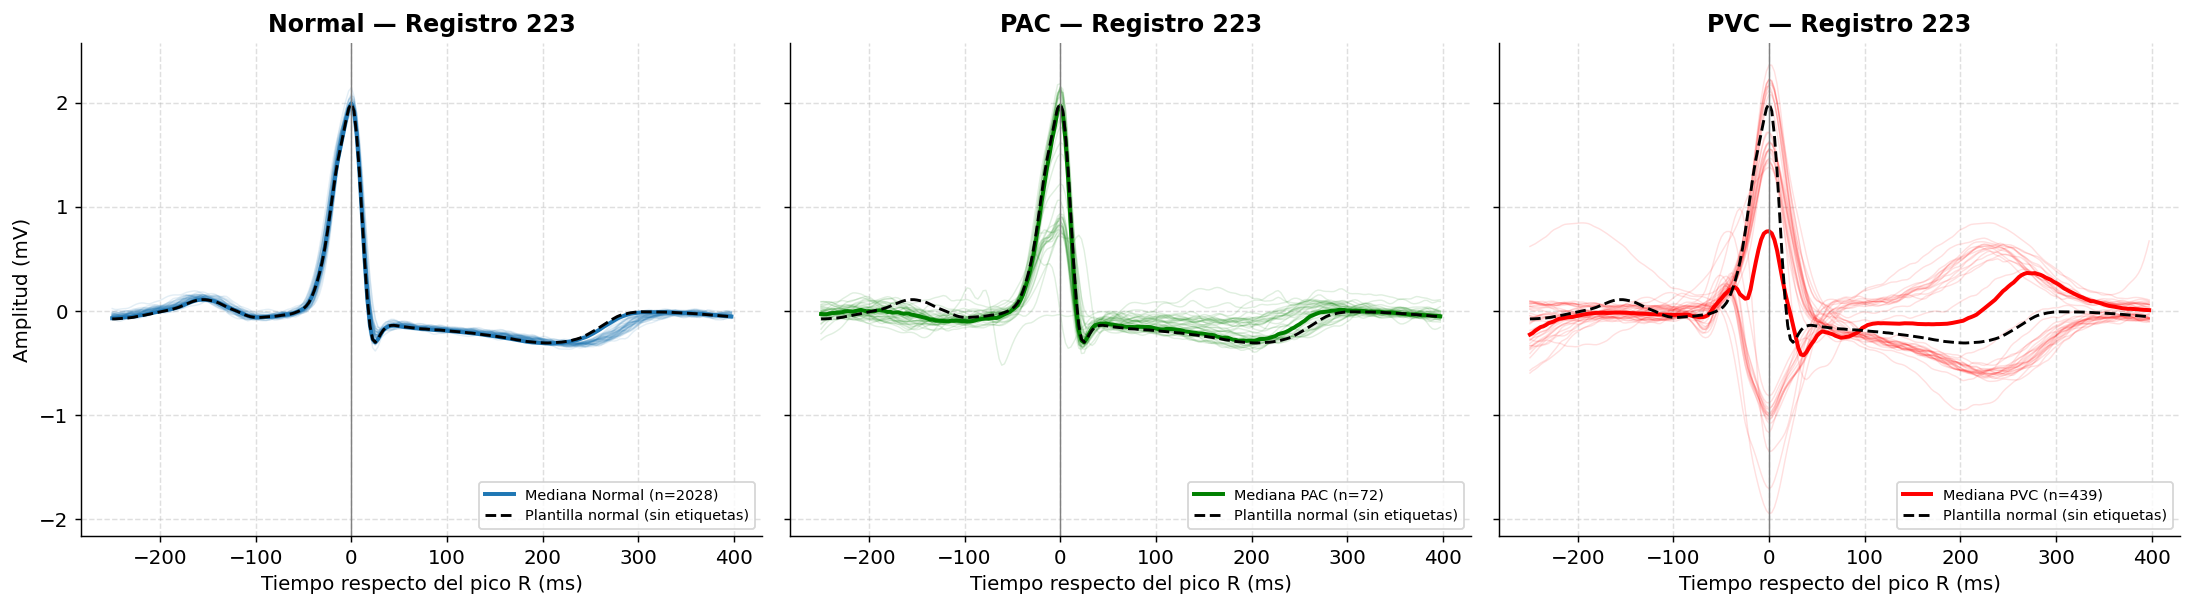

In [14]:
# CELDA 10 - Segmentación y plantilla normal por paciente

PRE_MS, POST_MS = 250, 400     # ventana del latido: 250 ms antes y 400 ms después del pico R

def ms2n(ms, fs):
    """Convierte milisegundos a cantidad de muestras."""
    return int(round(ms * fs / 1000))


def segmentar(señal, picos_r, fs, pre_ms=PRE_MS, post_ms=POST_MS):
    """
    Recorta cada latido en una ventana alrededor del pico R.
    Devuelve una matriz (n_latidos x muestras). Los latidos que
    no entran completos (bordes del registro) quedan con NaN.
    """
    pre, post = ms2n(pre_ms, fs), ms2n(post_ms, fs)
    latidos = np.full((len(picos_r), pre + post), np.nan)
    for k, p in enumerate(picos_r):
        if p - pre >= 0 and p + post <= len(señal):
            latidos[k] = señal[p - pre:p + post]
    return latidos


def corr(a, b):
    """Correlación de Pearson entre dos tramos de señal."""
    if np.std(a) < 1e-9 or np.std(b) < 1e-9:
        return 0.0
    return float(np.corrcoef(a, b)[0, 1])


def plantilla_normal(latidos, picos_r, fs, margen=0.10, corr_min=0.9):
    """
    Latido normal de referencia del paciente, construido SIN etiquetas:
    mediana de los latidos rítmicos (RR previo y posterior dentro de
    ±10 % del RR mediano), refinada con los que se parecen a ella.
    """
    rr = np.diff(picos_r) / fs * 1000
    rr_med = np.median(rr)
    ritmicos = [k for k in range(1, len(picos_r) - 1)
                if abs(rr[k - 1] - rr_med) <= margen * rr_med
                and abs(rr[k] - rr_med) <= margen * rr_med
                and not np.isnan(latidos[k, 0])]
    # Registro muy arrítmico: se usan todos los latidos válidos
    if len(ritmicos) < 10:
        ritmicos = [k for k in range(len(picos_r)) if not np.isnan(latidos[k, 0])]

    plantilla = np.median(latidos[ritmicos], axis=0)

    # Refinamiento: quedarse con los latidos que se parecen a la plantilla inicial
    buenos = [k for k in ritmicos if corr(latidos[k], plantilla) >= corr_min]
    if len(buenos) >= 10:
        plantilla = np.median(latidos[buenos], axis=0)
    return plantilla, len(buenos)


# Ejemplo sobre el registro 223 ─────────────────────────────────
picos_ej, c0_ej, _, fs_ej, ref_pos_ej, ref_sym_ej = detectar_qrs('223')
lat_ej = segmentar(c0_ej, picos_ej, fs_ej)
plantilla_ej, n_pl = plantilla_normal(lat_ej, picos_ej, fs_ej)
print(f"Registro 223: {len(picos_ej)} latidos detectados, "
      f"plantilla construida con {n_pl} latidos rítmicos")

# Etiqueta de cada latido detectado (solo para el gráfico)
ref_de_det, _ = match_detecciones_referencia(picos_ej, ref_pos_ej, fs_ej)
clase_ej = np.where(ref_de_det >= 0, ref_sym_ej[np.maximum(ref_de_det, 0)], 'FP')

t_lat = (np.arange(lat_ej.shape[1]) - ms2n(PRE_MS, fs_ej)) / fs_ej * 1000
colores = {'N': '#1f77b4', 'A': 'green', 'V': 'red'}
nombres = {'N': 'Normal', 'A': 'PAC', 'V': 'PVC'}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for ax, c in zip(axes, ['N', 'A', 'V']):
    sel = lat_ej[(clase_ej == c) & ~np.isnan(lat_ej[:, 0])]
    for x in sel[:40]:
        ax.plot(t_lat, x, color=colores[c], alpha=0.12, lw=0.8)
    if len(sel):
        ax.plot(t_lat, np.median(sel, axis=0), color=colores[c], lw=2.2,
                label=f'Mediana {nombres[c]} (n={len(sel)})')
    ax.plot(t_lat, plantilla_ej, 'k--', lw=1.6, label='Plantilla normal (sin etiquetas)')
    ax.axvline(0, color='gray', lw=0.8)
    ax.set_title(f'{nombres[c]} — Registro 223', fontweight='bold')
    ax.set_xlabel('Tiempo respecto del pico R (ms)')
    ax.grid(True, ls='--', alpha=0.4)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(fontsize=8, loc='lower right')
axes[0].set_ylabel('Amplitud (mV)')
plt.tight_layout()
plt.savefig('06_latidos_por_clase.png', bbox_inches='tight')
plt.show()

## Extracción de características

Para cada latido se calculan 13 características, agrupadas en tres tipos. Cada una se eligió porque refleja una diferencia fisiológica entre latidos normales, PAC y PVC.

### 1. Características temporales:

- **RR previo y RR posterior (ms):** tiempo desde el latido anterior y hasta el siguiente.
- **Prematuridad = RR previo / RR local:** cuánto se adelantó el latido respecto del ritmo del paciente en ese momento. El RR local es la mediana de los RR de los ±8 latidos vecinos, así el valor no depende de si el paciente tiene el corazón más rápido o más lento. Vale ~1 en latidos normales y menos de 1 en PAC y PVC.
- **Pausa compensatoria = (RR previo + RR posterior) / (2 · RR local):** después de un PVC el nodo sinusal no se reinicia, el ritmo "recupera" el tiempo y la pausa es completa (valor ≈ 1). Un PAC sí reinicia el nodo sinusal, por lo que la pausa es incompleta (valor < 1).

### 2. Características morfológicas:

- **Ancho del QRS (ms):** en un PVC el impulso se propaga lentamente por el músculo ventricular, sin usar el sistema de conducción rápido, por lo que el QRS es ancho. Acá se mide el tramo donde la señal supera el 15 % del pico, así que los valores son menores que los clínicos (no se usa el umbral de 120 ms), pero sirven para comparar latidos entre sí.
- **Área del QRS:** área bajo el valor absoluto del QRS. Combina ancho y amplitud, y es mayor en los PVC.
- **Amplitud relativa:** amplitud del QRS dividida por la amplitud del QRS de la plantilla normal.

### 3. Características de correlación:

- **Correlación del QRS:** correlación de Pearson entre el QRS del latido (±60 ms) y el de la plantilla normal. Es alta en normales y PAC, y baja en PVC.
- **Correlación cruzada máxima del QRS:** igual que la anterior, pero probando pequeños desplazamientos (±30 ms) y quedándose con el mejor. Así no se penaliza un error chico en la ubicación del pico R.
- **Correlación del latido completo:** correlación de toda la ventana (onda P, QRS y onda T) con la plantilla. Incluye la onda T, que en los PVC suele estar invertida.
- **Correlación de la onda P:** correlación de la ventana de −250 a −80 ms con la de la plantilla. Un PAC se origina en otro lugar de la aurícula, por lo que su onda P tiene otra forma o queda superpuesta a la onda T anterior. Es la característica mas importante para diferenciar PAC de normales.
- **Correlación con el latido anterior:** correlación del QRS con el QRS del latido previo. Detecta un cambio brusco de forma.
- **Error cuadrático normalizado:** diferencia punto a punto entre el latido y la plantilla, dividida por la amplitud de la plantilla. Complementa a la correlación, que no tiene en cuenta la amplitud.

Todas las características se miden sobre la derivación MLII. No se usa el segundo canal porque cambia según el registro (V1, V2, V4 o V5), y una característica medida en derivaciones distintas no sería comparable entre pacientes.

In [15]:
# CELDA 11 - Funciones de extracción de características

def ancho_qrs(señal, p, fs, frac=0.15, max_ms=250):
    """
    Ancho del QRS: desde el pico R se avanza hacia ambos lados hasta que
    la señal cae por debajo del 15 % de la amplitud del complejo.
    """
    hw = ms2n(max_ms / 2, fs)
    v = señal[max(0, p - hw):p + hw]
    seg = v - np.median(v)
    amp = np.max(np.abs(seg))
    if amp < 1e-9:
        return np.nan
    c = p - max(0, p - hw)
    li, ld = c, c
    while li > 0 and abs(seg[li]) >= frac * amp:
        li -= 1
    while ld < len(seg) - 1 and abs(seg[ld]) >= frac * amp:
        ld += 1
    return (ld - li) / fs * 1000


def xcorr_max(a, b, max_lag):
    """Máxima correlación entre a y b desplazando hasta ±max_lag muestras."""
    mejor = -1.0
    n = len(a)
    for lag in range(-max_lag, max_lag + 1):
        if lag >= 0:
            x, y = a[lag:], b[:n - lag]
        else:
            x, y = a[:n + lag], b[-lag:]
        mejor = max(mejor, corr(x, y))
    return mejor


def extraer_caracteristicas(señal, picos_r, fs):
    """
    Calcula las 13 características de cada latido de un registro.
    Devuelve una tabla (un latido por fila), la plantilla normal
    y la cantidad de latidos usados para construirla.
    """
    latidos = segmentar(señal, picos_r, fs)
    plantilla, n_plantilla = plantilla_normal(latidos, picos_r, fs)

    pre = ms2n(PRE_MS, fs)                              # posición del pico R en la ventana
    q0, q1 = pre - ms2n(60, fs), pre + ms2n(60, fs)     # ventana del QRS (±60 ms)
    p0, p1 = pre - ms2n(250, fs), pre - ms2n(80, fs)    # ventana de la onda P
    lag = ms2n(30, fs)                                  # desplazamiento máximo (±30 ms)

    amp_pl = np.max(np.abs(plantilla[q0:q1] - np.median(plantilla)))
    qrs_pl = plantilla[q0:q1]
    rr = np.diff(picos_r) / fs * 1000

    filas = []
    for k in range(1, len(picos_r) - 1):
        lat = latidos[k]
        if np.isnan(lat[0]) or np.isnan(latidos[k - 1, 0]):
            continue
        rr_prev, rr_post = rr[k - 1], rr[k]
        rr_local = np.median(rr[max(0, k - 8):k + 8])
        qrs = lat[q0:q1]
        base = np.median(lat)

        filas.append({
            'idx': k,
            'muestra': picos_r[k],
            # Temporales
            'rr_prev': rr_prev,
            'rr_post': rr_post,
            'prematuridad': rr_prev / rr_local,
            'pausa_comp': (rr_prev + rr_post) / (2 * rr_local),
            # Morfológicas
            'ancho_qrs': ancho_qrs(señal, picos_r[k], fs),
            'area_qrs': np.trapezoid(np.abs(qrs - base), dx=1000 / fs),
            'amp_rel': np.max(np.abs(qrs - base)) / amp_pl if amp_pl > 1e-9 else np.nan,
            # Correlación con la plantilla normal
            'corr_qrs': corr(qrs, qrs_pl),
            'xcorr_qrs': xcorr_max(lat[q0 - lag:q1 + lag], plantilla[q0 - lag:q1 + lag], lag),
            'corr_latido': corr(lat, plantilla),
            'corr_p': corr(lat[p0:p1], plantilla[p0:p1]),
            'corr_prev': corr(qrs, latidos[k - 1][q0:q1]),
            'rmse_norm': np.sqrt(np.mean((lat - plantilla) ** 2)) / amp_pl if amp_pl > 1e-9 else np.nan,
        })
    return pd.DataFrame(filas), plantilla, n_plantilla


FEATURES = ['rr_prev', 'rr_post', 'prematuridad', 'pausa_comp',
            'ancho_qrs', 'area_qrs', 'amp_rel',
            'corr_qrs', 'xcorr_qrs', 'corr_latido', 'corr_p', 'corr_prev', 'rmse_norm']

print("Funciones de extracción definidas. Características:", len(FEATURES))

Funciones de extracción definidas. Características: 13


### Aplicación a toda la base y etiquetado

Para cada uno de los 44 registros se detectan los latidos y se calculan sus características. Después, cada latido detectado se asocia con la anotación de MIT-BIH más cercana (tolerancia de ±150 ms) para conocer su clase real.


El resultado es una tabla con un latido por fila: sus 13 características, su clase real, el registro al que pertenece y si es de DS1 o DS2.

In [17]:
# CELDA 12 - Características de todos los latidos de la base

tablas, plantillas = [], {}

for k, reg in enumerate(registros_uso, 1):
    picos, c0, _, fs_r, ref_pos, ref_sym = detectar_qrs(reg)

    df_f, plantilla, n_pl = extraer_caracteristicas(c0, picos, fs_r)
    plantillas[reg] = plantilla

    # Clase real de cada latido detectado (anotación más cercana, ±150 ms)
    ref_de_det, _ = match_detecciones_referencia(picos, ref_pos, fs_r)
    idx_ref = ref_de_det[df_f['idx'].values]
    df_f['clase'] = np.where(idx_ref >= 0, ref_sym[np.maximum(idx_ref, 0)], 'FP')
    df_f['registro'] = reg
    df_f['subconjunto'] = 'DS1' if reg in DS1 else 'DS2'
    tablas.append(df_f)

    print(f"({k}/{len(registros_uso)}) {reg}: {len(df_f)} latidos, "
          f"plantilla con {n_pl} latidos rítmicos")

df_todo = pd.concat(tablas, ignore_index=True)

# Dataset final: solo latidos N, A y V con todas las características calculadas
df_lat = df_todo[df_todo['clase'].isin(['N', 'A', 'V'])].dropna(subset=FEATURES).reset_index(drop=True)
df_ds1 = df_lat[df_lat['subconjunto'] == 'DS1']
df_ds2 = df_lat[df_lat['subconjunto'] == 'DS2']

print(f"\nLatidos totales detectados: {len(df_todo)}")
print(f"Latidos N/A/V para el análisis: {len(df_lat)}")
print("\nLatidos por clase y subconjunto:")
display(pd.crosstab(df_lat['subconjunto'], df_lat['clase'], margins=True, margins_name='Total'))

print("\nPrimeras filas de la tabla de características:")
display(df_lat[['registro', 'clase'] + FEATURES].head(10).round(3))

(1/44) 100: 2270 latidos, plantilla con 2046 latidos rítmicos
(2/44) 101: 1867 latidos, plantilla con 1542 latidos rítmicos
(3/44) 103: 2108 latidos, plantilla con 1882 latidos rítmicos
(4/44) 105: 2565 latidos, plantilla con 2006 latidos rítmicos
(5/44) 106: 1811 latidos, plantilla con 465 latidos rítmicos
(6/44) 108: 1750 latidos, plantilla con 653 latidos rítmicos
(7/44) 109: 2528 latidos, plantilla con 2317 latidos rítmicos
(8/44) 111: 2124 latidos, plantilla con 1744 latidos rítmicos
(9/44) 112: 2537 latidos, plantilla con 2520 latidos rítmicos
(10/44) 113: 1793 latidos, plantilla con 968 latidos rítmicos
(11/44) 114: 1877 latidos, plantilla con 874 latidos rítmicos
(12/44) 115: 1956 latidos, plantilla con 1206 latidos rítmicos
(13/44) 116: 2412 latidos, plantilla con 1978 latidos rítmicos
(14/44) 117: 1533 latidos, plantilla con 867 latidos rítmicos
(15/44) 118: 2275 latidos, plantilla con 1523 latidos rítmicos
(16/44) 119: 1986 latidos, plantilla con 789 latidos rítmicos
(17/44)

clase,A,N,V,Total
subconjunto,,,,
DS1,810,37768,3475,42053
DS2,1735,36195,3182,41112
Total,2545,73963,6657,83165



Primeras filas de la tabla de características:


,registro,clase,rr_prev,rr_post,prematuridad,pausa_comp,ancho_qrs,area_qrs,amp_rel,corr_qrs,xcorr_qrs,corr_latido,corr_p,corr_prev,rmse_norm
0,100,N,813.889,788.889,1.002,0.986,27.778,27.011,0.998,0.996,0.996,0.992,0.809,0.963,0.020
1,100,N,788.889,788.889,0.973,0.973,27.778,28.001,0.942,0.994,0.994,0.984,0.982,0.995,0.029
2,100,N,788.889,788.889,0.984,0.984,27.778,23.924,0.897,0.989,0.989,0.989,0.982,0.981,0.030
3,100,N,788.889,816.667,0.973,0.990,27.778,25.651,0.945,0.997,0.997,0.994,0.978,0.996,0.020
4,100,N,816.667,655.556,1.005,0.906,30.556,27.743,0.976,0.985,0.989,0.985,0.984,0.988,0.026
5,100,A,655.556,994.444,0.805,1.014,30.556,26.818,0.939,0.988,0.989,0.984,0.817,0.949,0.028
6,100,N,994.444,841.667,1.222,1.128,33.333,29.584,0.976,0.993,0.993,0.981,0.961,0.980,0.029
7,100,N,841.667,811.111,1.032,1.014,30.556,27.503,0.961,0.999,0.999,0.998,0.979,0.990,0.013
8,100,N,811.111,791.667,0.997,0.985,27.778,25.875,0.964,0.993,0.993,0.991,0.852,0.992,0.023
9,100,N,791.667,769.444,0.973,0.959,27.778,24.544,0.887,0.995,0.995,0.992,0.883,0.999,0.028


# Análisis estadístico de las características

Antes de construir cualquier clasificador se evalúa qué características diferencian realmente a las tres clases y cuánto las diferencian. Así, el clasificador se basa en características justificadas y no elegidas sin sentido.

El análisis se hace solo con DS1, para que la elección de características no use información de los pacientes con los que después se va a evaluar.

Se hace con test no parametricos, ya que los tests clásicos (ANOVA, test t) suponen que los datos tienen distribución normal. Esto no se cumple acá:
- las correlaciones están acotadas entre −1 y 1, y se acumulan cerca de 1.
- varias características son muy asimétricas, como el ancho del QRS o el RR posterior.

Por eso al usar tests no paramétricos, se comparan rangos (el orden de los valores) en lugar de los valores mismos, y no suponen ninguna distribución.

Primero se muestra la mediana y el rango intercuartil de cada característica en cada clase. Se usa la mediana en lugar del promedio por la misma razón: es robusta frente a valores extremos.

In [18]:
# CELDA 13 - Estadística descriptiva por clase (DS1)
from scipy.stats import kruskal, mannwhitneyu

CLASES = ['N', 'A', 'V']
NOMBRES_CLASE = {'N': 'Normal', 'A': 'PAC', 'V': 'PVC'}

def mediana_iqr(x):
    return f"{np.median(x):.3g} [{np.percentile(x, 25):.3g} – {np.percentile(x, 75):.3g}]"

desc = df_ds1.groupby('clase')[FEATURES].agg(mediana_iqr).T
desc = desc[CLASES]
desc.columns = [NOMBRES_CLASE[c] for c in CLASES]

print("Mediana [Q1 – Q3] de cada característica por clase — DS1")
print("Latidos por clase:", df_ds1['clase'].value_counts()[CLASES].to_dict())
display(desc)

Mediana [Q1 – Q3] de cada característica por clase — DS1
Latidos por clase: {'N': 37768, 'A': 810, 'V': 3475}


,Normal,PAC,PVC
rr_prev,744 [667 – 911],486 [394 – 547],525 [461 – 567]
rr_post,728 [636 – 889],562 [394 – 800],858 [650 – 1.24e+03]
prematuridad,1 [0.982 – 1.03],0.85 [0.732 – 0.989],0.761 [0.634 – 0.887]
pausa_comp,1 [0.983 – 1.02],0.967 [0.914 – 1],1.01 [0.952 – 1.06]
ancho_qrs,38.9 [33.3 – 52.8],36.1 [30.6 – 52.8],94.4 [75 – 108]
area_qrs,50.4 [36.1 – 67.5],42.5 [37.2 – 65.6],118 [67.6 – 137]
amp_rel,0.993 [0.931 – 1.05],1.05 [0.97 – 1.15],0.968 [0.657 – 1.23]
corr_qrs,0.994 [0.987 – 0.997],0.988 [0.978 – 0.993],0.584 [-0.362 – 0.692]
xcorr_qrs,0.994 [0.99 – 0.997],0.987 [0.98 – 0.994],0.64 [0.554 – 0.772]
corr_latido,0.987 [0.971 – 0.993],0.893 [0.685 – 0.957],0.343 [-0.211 – 0.42]


## Tests de hipótesis y tamaño del efecto

**1. Test de Kruskal-Wallis (las tres clases a la vez)**

Para cada característica se plantea:
- H₀: la característica tiene la misma distribución en las tres clases.
- H₁: al menos una clase es distinta.

El test ordena todos los latidos de menor a mayor y compara el rango promedio de cada clase. Si una clase tiende a tener valores más altos o más bajos que las otras, el estadístico H crece y el p-valor baja.

**2. Comparaciones de a pares (post-hoc)**

Kruskal-Wallis dice si *alguna* clase es distinta, pero no *cuál*. Por eso después se compara cada par de clases (Normal–PAC, Normal–PVC y PAC–PVC) con el test U de Mann-Whitney. Como se hacen 3 comparaciones, aumenta la chance de encontrar una diferencia por azar; para compensarlo se aplica la corrección de Bonferroni: cada p-valor se multiplica por 3.

**3. Tamaño del efecto**

Con decenas de miles de latidos, cualquier diferencia mínima da p < 0,001. El p-valor solo dice que hay diferencia, no si es grande. Por eso lo importante es el tamaño del efecto:

- **ε² (épsilon cuadrado)** para Kruskal-Wallis: qué proporción de la variabilidad se explica por la clase. Va de 0 a 1.

$$\varepsilon^2 = \frac{H}{n - 1}$$

- **δ de Cliff** para cada par de clases: si se toma un latido al azar de cada clase, mide qué tan probable es que el de una clase tenga un valor mayor que el de la otra. Va de −1 a 1: 0 significa que las clases se superponen totalmente, y ±1 que están completamente separadas. El signo indica cuál de las dos tiene valores mayores.

$$\delta = \frac{2U}{n_1 \, n_2} - 1$$

Interpretación habitual del δ de Cliff (Romano et al., 2006): |δ| < 0,147 despreciable; < 0,33 pequeño; < 0,474 mediano; ≥ 0,474 grande.

**4. Análisis por paciente**

Los latidos de una misma persona no son independientes entre sí, y los tests suponen que sí lo son. Además, un paciente con muchos latidos pesa más que uno con pocos. Para controlar esto, el análisis se repite tomando un valor por paciente: la mediana de cada característica en cada registro y clase. Si una característica sigue separando las clases en este análisis, la diferencia es consistente entre pacientes y no se debe a uno solo.

In [19]:
# CELDA 14 - Kruskal-Wallis, post-hoc (Mann-Whitney + Bonferroni) y tamaños de efecto

PARES = [('N', 'A'), ('N', 'V'), ('A', 'V')]

def cliff_delta(x, y):
    """δ de Cliff calculado a partir del estadístico U de Mann-Whitney."""
    U = mannwhitneyu(x, y, alternative='two-sided').statistic
    return 2 * U / (len(x) * len(y)) - 1


def magnitud(d):
    d = abs(d)
    if d < 0.147: return 'despreciable'
    if d < 0.33:  return 'pequeño'
    if d < 0.474: return 'mediano'
    return 'grande'


def tabla_estadistica(df, features):
    filas = []
    for f in features:
        grupos = {c: df.loc[df['clase'] == c, f].values for c in CLASES}
        if any(len(g) < 2 for g in grupos.values()):
            continue
        H, p = kruskal(*grupos.values())
        n = sum(len(g) for g in grupos.values())
        fila = {'Característica': f, 'H': H, 'p (KW)': p, 'ε²': H / (n - 1)}
        for a, b in PARES:
            p_ab = mannwhitneyu(grupos[a], grupos[b], alternative='two-sided').pvalue
            fila[f'δ {a}-{b}'] = cliff_delta(grupos[a], grupos[b])
            fila[f'p {a}-{b}'] = min(p_ab * len(PARES), 1.0)     # Bonferroni
        filas.append(fila)
    return pd.DataFrame(filas).set_index('Característica').sort_values('ε²', ascending=False)


def resumen_legible(est):
    """Tabla resumida: ε² y magnitud del efecto en cada par (* = no significativo)."""
    res = pd.DataFrame(index=est.index)
    res['ε²'] = est['ε²'].round(3)
    for a, b in PARES:
        col = f'{NOMBRES_CLASE[a]} vs {NOMBRES_CLASE[b]}'
        res[col] = [f"{d:+.2f} ({magnitud(d)}){'' if p < 0.05 else ' *'}"
                    for d, p in zip(est[f'δ {a}-{b}'], est[f'p {a}-{b}'])]
    return res


# 1) Análisis por LATIDO
est_latidos = tabla_estadistica(df_ds1, FEATURES)
print("ANÁLISIS POR LATIDO (DS1) — tabla completa")
display(est_latidos.style.format('{:.3g}'))
print("Resumen: δ de Cliff y magnitud del efecto (* = no significativo tras Bonferroni)")
display(resumen_legible(est_latidos))

# 2) Análisis por PACIENTE: mediana de cada característica por registro y clase
df_pac = df_ds1.groupby(['registro', 'clase'])[FEATURES].median().reset_index()
print("\nRegistros de DS1 que aportan cada clase:",
      df_pac['clase'].value_counts()[CLASES].to_dict())
est_pacientes = tabla_estadistica(df_pac, FEATURES)
print("ANÁLISIS POR PACIENTE (una mediana por registro y clase, DS1)")
display(resumen_legible(est_pacientes))

ANÁLISIS POR LATIDO (DS1) — tabla completa


,H,p (KW),ε²,δ N-A,p N-A,δ N-V,p N-V,δ A-V,p A-V
Característica,,,,,,,,,
rmse_norm,9.58e+03,0,0.228,-0.666,1.04e-230,-0.953,0,-0.913,0
corr_latido,9.54e+03,0,0.227,0.701,1.25e-255,0.946,0,0.923,0
xcorr_qrs,9.43e+03,0,0.224,0.408,7.61e-88,0.975,0,0.995,0
corr_qrs,8.84e+03,0,0.21,0.325,5.98e-56,0.949,0,0.991,0
corr_p,8.29e+03,0,0.197,0.718,2e-268,0.873,0,0.458,2.3e-91
ancho_qrs,7.16e+03,0,0.17,0.152,3.02e-13,-0.86,0,-0.826,1.2e-294
prematuridad,6.82e+03,0,0.162,0.612,4.09e-195,0.8,0,0.274,1.87e-33
corr_prev,6.57e+03,0,0.156,0.0161,1,0.827,0,0.9,0
rr_prev,6.34e+03,0,0.151,0.872,0,0.707,0,-0.222,2.24e-22


Resumen: δ de Cliff y magnitud del efecto (* = no significativo tras Bonferroni)


,ε²,Normal vs PAC,Normal vs PVC,PAC vs PVC
Característica,,,,
rmse_norm,0.228,-0.67 (grande),-0.95 (grande),-0.91 (grande)
corr_latido,0.227,+0.70 (grande),+0.95 (grande),+0.92 (grande)
xcorr_qrs,0.224,+0.41 (mediano),+0.97 (grande),+1.00 (grande)
corr_qrs,0.210,+0.32 (pequeño),+0.95 (grande),+0.99 (grande)
corr_p,0.197,+0.72 (grande),+0.87 (grande),+0.46 (mediano)
ancho_qrs,0.170,+0.15 (pequeño),-0.86 (grande),-0.83 (grande)
prematuridad,0.162,+0.61 (grande),+0.80 (grande),+0.27 (pequeño)
corr_prev,0.156,+0.02 (despreciable) *,+0.83 (grande),+0.90 (grande)
rr_prev,0.151,+0.87 (grande),+0.71 (grande),-0.22 (pequeño)



Registros de DS1 que aportan cada clase: {'N': 18, 'A': 14, 'V': 17}
ANÁLISIS POR PACIENTE (una mediana por registro y clase, DS1)


,ε²,Normal vs PAC,Normal vs PVC,PAC vs PVC
Característica,,,,
corr_latido,0.755,+0.60 (grande),+1.00 (grande),+1.00 (grande)
rmse_norm,0.738,-0.53 (grande),-1.00 (grande),-1.00 (grande)
corr_qrs,0.709,+0.37 (mediano) *,+1.00 (grande),+1.00 (grande)
xcorr_qrs,0.705,+0.35 (mediano) *,+1.00 (grande),+1.00 (grande)
prematuridad,0.681,+0.96 (grande),+1.00 (grande),-0.05 (despreciable) *
corr_prev,0.672,+0.11 (despreciable) *,+0.99 (grande),+1.00 (grande)
ancho_qrs,0.530,-0.18 (pequeño) *,-0.89 (grande),-0.85 (grande)
corr_p,0.521,+0.87 (grande),+0.86 (grande),+0.07 (despreciable) *
rr_prev,0.399,+0.80 (grande),+0.72 (grande),+0.00 (despreciable) *


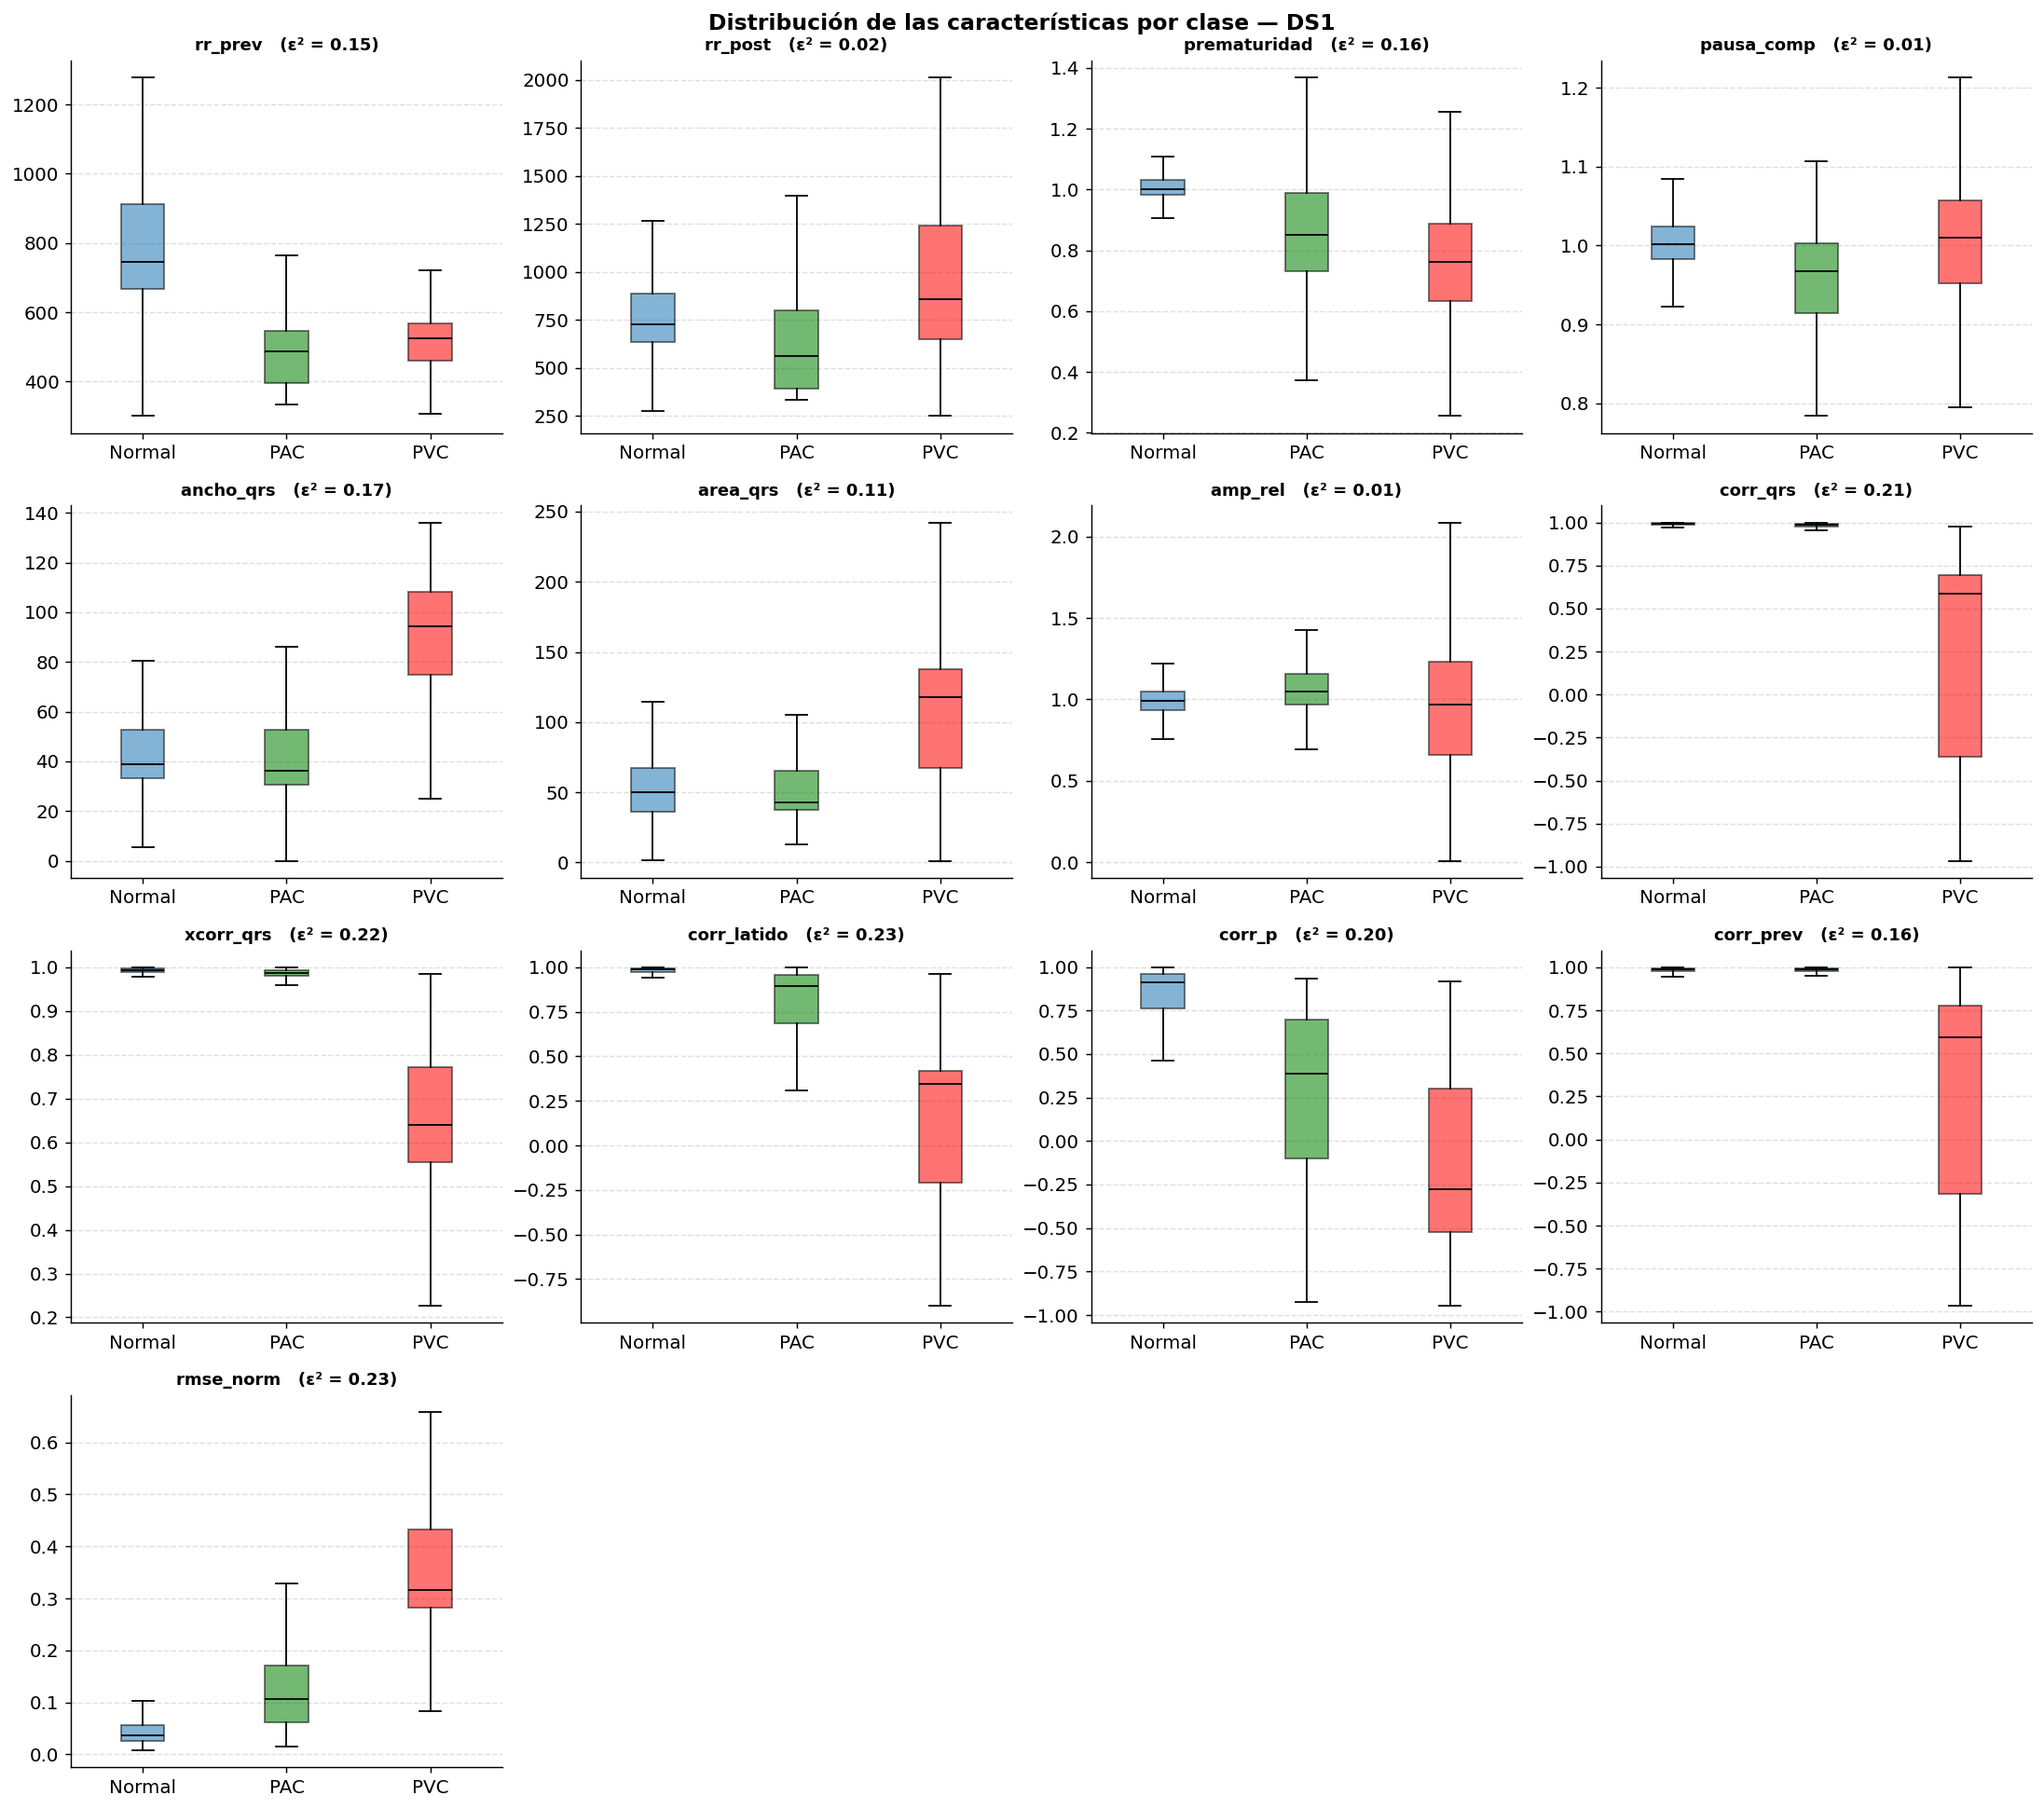

In [20]:
# CELDA 15 - Boxplots de las características por clase (DS1)

colores = {'N': '#1f77b4', 'A': 'green', 'V': 'red'}
n_col = 4
n_fil = int(np.ceil(len(FEATURES) / n_col))
fig, axes = plt.subplots(n_fil, n_col, figsize=(17, 3.8 * n_fil))
axes = axes.ravel()

for ax, f in zip(axes, FEATURES):
    datos = [df_ds1.loc[df_ds1['clase'] == c, f] for c in CLASES]
    bp = ax.boxplot(datos, tick_labels=[NOMBRES_CLASE[c] for c in CLASES],
                    showfliers=False, patch_artist=True)
    for patch, c in zip(bp['boxes'], CLASES):
        patch.set_facecolor(colores[c]); patch.set_alpha(0.55)
    for med in bp['medians']:
        med.set_color('black')
    ax.set_title(f"{f}   (ε² = {est_latidos.loc[f, 'ε²']:.2f})", fontsize=10, fontweight='bold')
    ax.grid(axis='y', ls='--', alpha=0.4)
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes[len(FEATURES):]:
    ax.axis('off')

plt.suptitle('Distribución de las características por clase — DS1', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('07_boxplots_caracteristicas.png', bbox_inches='tight')
plt.show()

### Redundancia entre características

Dos características pueden medir prácticamente lo mismo. Por ejemplo, la correlación del QRS y la correlación cruzada máxima del QRS son casi la misma medida. Si están muy relacionadas, una de ellas no aporta información nueva.

Para detectarlo se calcula la correlación de Spearman entre cada par de características. Spearman es la versión por rangos de la correlación de Pearson: mide si cuando una aumenta la otra también tiende a aumentar (o a disminuir), aunque la relación no sea lineal. Se consideran redundantes los pares con |ρ| > 0,85.

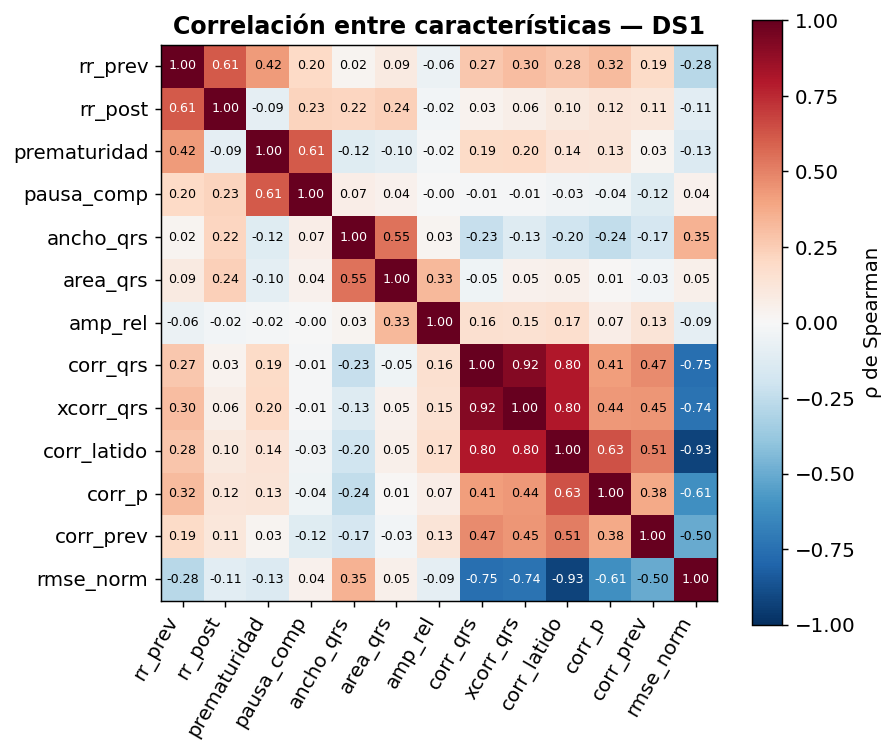

Pares redundantes (|ρ| > 0,85):
   corr_qrs  ↔  xcorr_qrs:  ρ = 0.92
   corr_latido  ↔  rmse_norm:  ρ = -0.93


In [22]:
# CELDA 16 - Correlación de Spearman entre características (DS1)

rho = df_ds1[FEATURES].corr(method='spearman')

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(rho, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES, rotation=60, ha='right')
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f'{rho.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(rho.iloc[i, j]) > 0.6 else 'black')
plt.colorbar(im, label='ρ de Spearman')
plt.title('Correlación entre características — DS1', fontweight='bold')
plt.tight_layout()
plt.savefig('08_spearman.png', bbox_inches='tight')
plt.show()

redundantes = [(a, b, round(rho.loc[a, b], 2))
               for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:]
               if abs(rho.loc[a, b]) > 0.85]
print("Pares redundantes (|ρ| > 0,85):")
for a, b, r in redundantes:
    print(f"   {a}  ↔  {b}:  ρ = {r}")

## Clasificación de latidos

Se comparan dos clasificadores: uno por reglas, construido a partir del análisis estadístico, y un Random Forest. Los dos se ajustan con los pacientes de DS1 y se evalúan con los pacientes de DS2, que no se usaron en ningún paso anterior.

### Medicion del desempeño

Se usan las mismas métricas que en la detección (sensibilidad, valor predictivo positivo y F1), pero calculadas para cada clase

Además se muestra la matriz de confusión: una tabla donde las filas son la clase real y las columnas la clase que dijo el clasificador. La diagonal son los aciertos, y lo que queda fuera de la diagonal muestra exactamente qué se confunde con qué.

No se usa la exactitud global (porcentaje total de aciertos) como métrica principal: como casi el 89 % de los latidos son normales, un clasificador que dijera siempre "Normal" tendría 89 % de exactitud sin detectar ni un solo ectópico.

**Aclaración:** se evalúan los latidos que fueron detectados. Los PVC que Pan-Tompkins no detectó aprox. (3,5 %) nunca llegan al clasificador.

In [23]:
# CELDA 17 - Funciones de evaluación de la clasificación
from sklearn.metrics import precision_recall_fscore_support, roc_curve

def reporte(y_true, y_pred, titulo, archivo):
    """Tabla de Se, Pp y F1 por clase + matrices de confusión."""
    pp, se, f1, n = precision_recall_fscore_support(y_true, y_pred, labels=CLASES, zero_division=0)
    tabla = pd.DataFrame({'Se': se, 'Pp': pp, 'F1': f1, 'n latidos': n},
                         index=[NOMBRES_CLASE[c] for c in CLASES])
    tabla.loc['Promedio (macro)'] = [se.mean(), pp.mean(), f1.mean(), n.sum()]
    print(titulo)
    display(tabla.round(3))

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    for k, (norm, fmt, sub) in enumerate([(None, 'd', 'Cantidad de latidos'),
                                          ('true', '.2f', 'Proporción por clase real')]):
        cm = confusion_matrix(y_true, y_pred, labels=CLASES, normalize=norm)
        ConfusionMatrixDisplay(cm, display_labels=[NOMBRES_CLASE[c] for c in CLASES]).plot(
            ax=ax[k], cmap='Blues', values_format=fmt, colorbar=False)
        ax[k].set_title(sub)
        ax[k].set_xlabel('Clase predicha'); ax[k].set_ylabel('Clase real')
    plt.suptitle(titulo, fontweight='bold')
    plt.tight_layout()
    plt.savefig(archivo, bbox_inches='tight')
    plt.show()
    return tabla


def umbral_youden(valores, es_positivo, menor_es_positivo=True):
    """
    Umbral que maximiza Se + Especificidad − 1 (índice de Youden)
    sobre la curva ROC. Si menor_es_positivo=True, se considera
    positivo todo valor menor o igual al umbral.
    """
    puntaje = -valores if menor_es_positivo else valores
    fpr, tpr, thr = roc_curve(es_positivo, puntaje)
    mejor = np.argmax(tpr - fpr)
    return -thr[mejor] if menor_es_positivo else thr[mejor]

print("Funciones de evaluación definidas.")

Funciones de evaluación definidas.


## Clasificador por reglas

El análisis estadístico mostró que:
- los PVC se diferencian de normales y PAC por la forma del QRS (correlación del QRS con la plantilla normal);
- los PAC se diferencian de los normales porque llegan antes (prematuridad), mientras que su QRS es igual al normal.

Además, estas dos características son prácticamente independientes entre sí, por lo que cada una aporta información distinta. Con eso se arma una regla en dos pasos:

1. Si la correlación del QRS con la plantilla es menor que un umbral → **PVC**.
2. Si no, y la prematuridad es menor que otro umbral → **PAC**.
3. En cualquier otro caso → **Normal**.

El orden es importante porque primero se busca el PVC, porque también es prematuro. Si se preguntara primero por la prematuridad, los PVC terminarían clasificados como PAC.

### Eleccion de umbrales

Los umbrales se eligen con los pacientes de DS1, usando el índice de Youden. Para cada umbral posible se calcula cuántos latidos de la clase buscada se detectan (sensibilidad) y cuántos de las otras clases se descartan correctamente (especificidad). Se elige el umbral que maximiza:

$$J = Se + Esp - 1$$

Es decir, el punto de mejor equilibrio entre encontrar la clase buscada y no generar falsas alarmas. No se usan umbrales clínicos fijos porque las características no están en escala clínica: por ejemplo, el ancho del QRS se mide sobre la parte central del complejo.

- El umbral de la correlación del QRS se elige para separar PVC de todo lo demás.
- El umbral de la prematuridad se elige para separar PAC de normales, usando solo los latidos que no son PVC.

Umbrales elegidos con DS1:
   PVC si correlación del QRS ≤ 0.926
   PAC si prematuridad ≤ 0.926  (y no es PVC)

Clasificador por reglas — DS2


,Se,Pp,F1,n latidos
Normal,0.870,0.961,0.913,36195.0
PAC,0.213,0.107,0.142,1735.0
PVC,0.979,0.639,0.774,3182.0
Promedio (macro),0.687,0.569,0.610,41112.0


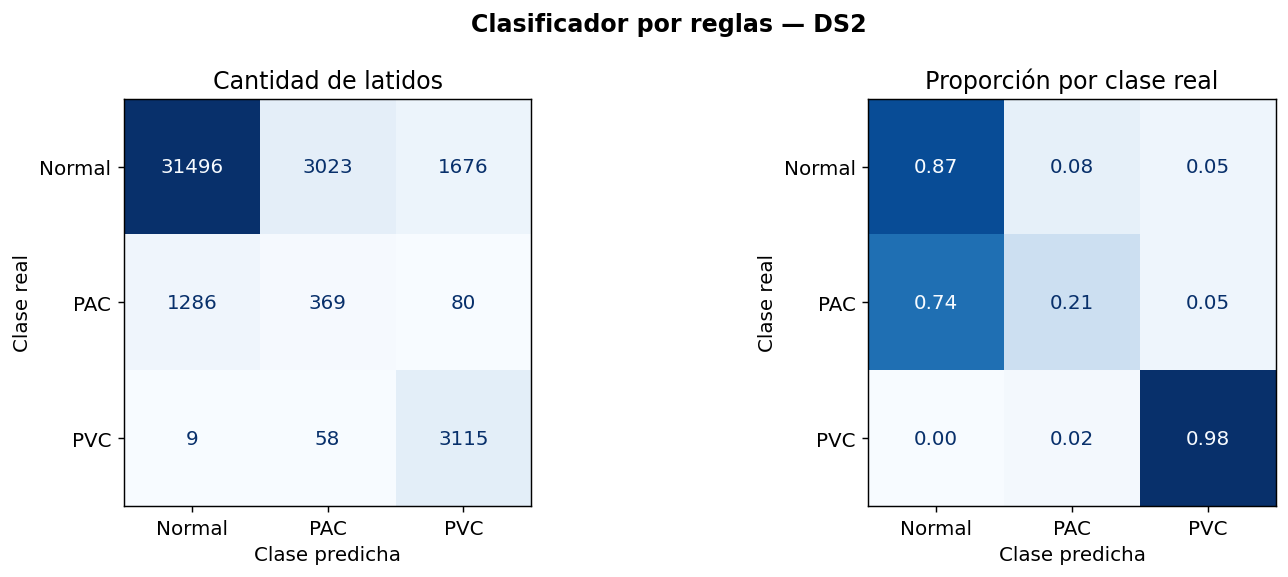

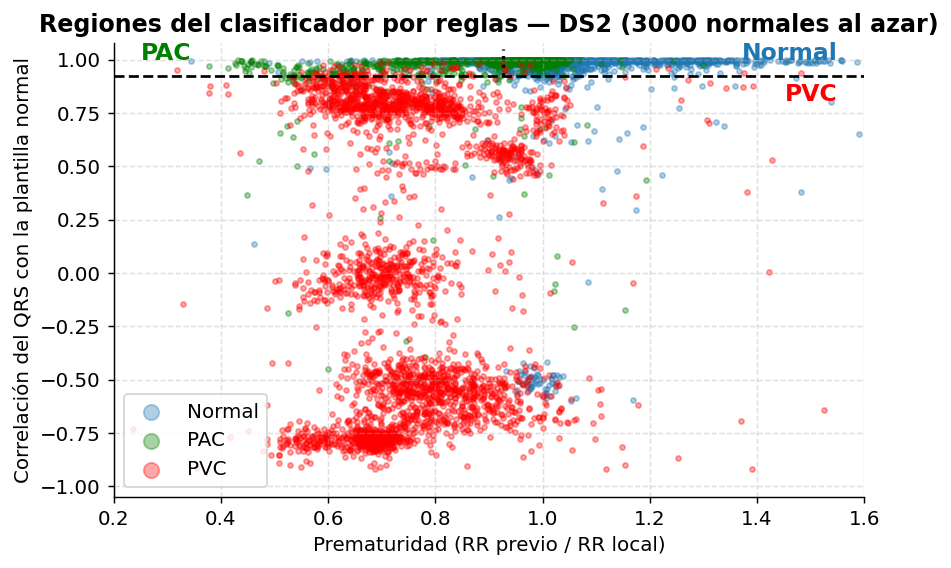

In [26]:
# CELDA 18 - Clasificador por reglas

# Umbrales elegidos con DS1 (índice de Youden)
thr_corr = umbral_youden(df_ds1['corr_qrs'].values, (df_ds1['clase'] == 'V').values)
no_v = df_ds1[df_ds1['clase'] != 'V']
thr_prem = umbral_youden(no_v['prematuridad'].values, (no_v['clase'] == 'A').values)

print("Umbrales elegidos con DS1:")
print(f"   PVC si correlación del QRS ≤ {thr_corr:.3f}")
print(f"   PAC si prematuridad ≤ {thr_prem:.3f}  (y no es PVC)\n")

def clasificar_reglas(df):
    pred = np.full(len(df), 'N', dtype=object)
    pred[df['prematuridad'].values <= thr_prem] = 'A'
    pred[df['corr_qrs'].values <= thr_corr] = 'V'    # va último: tiene prioridad sobre PAC
    return pred

# Evaluación sobre DS2 (pacientes nuevos)
res_reglas = reporte(df_ds2['clase'].values, clasificar_reglas(df_ds2),
                     'Clasificador por reglas — DS2', '09_cm_reglas.png')

# Gráfico de la regla: cada punto es un latido de DS2
muestra = pd.concat([df_ds2[df_ds2['clase'] == 'N'].sample(3000, random_state=42),
                     df_ds2[df_ds2['clase'] != 'N']])
fig, ax = plt.subplots(figsize=(7, 4.5))
for c, color in [('N', '#1f77b4'), ('A', 'green'), ('V', 'red')]:
    s = muestra[muestra['clase'] == c]
    ax.scatter(s['prematuridad'], s['corr_qrs'], s=8, alpha=0.35, color=color,
               label=NOMBRES_CLASE[c])
ax.axhline(thr_corr, color='black', ls='--', lw=1.5)
ax.plot([thr_prem, thr_prem], [thr_corr, 1.05], color='black', ls=':', lw=1.8)
ax.text(1.55, thr_corr - 0.12, 'PVC', fontsize=13, fontweight='bold', color='red', ha='right')
ax.text(0.25, 1.0, 'PAC', fontsize=13, fontweight='bold', color='green')
ax.text(1.55, 1.0, 'Normal', fontsize=13, fontweight='bold', color='#1f77b4', ha='right')
ax.set_xlim(0.2, 1.6); ax.set_ylim(-1.05, 1.08)
ax.set_xlabel('Prematuridad (RR previo / RR local)')
ax.set_ylabel('Correlación del QRS con la plantilla normal')
ax.set_title('Regiones del clasificador por reglas — DS2 (3000 normales al azar)', fontweight='bold')
ax.legend(loc='lower left', markerscale=3)
ax.grid(True, ls='--', alpha=0.4)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('10_regiones_reglas.png', bbox_inches='tight')
plt.show()

## Random Forest

El Random Forest es un clasificador formado por muchos árboles de decisión.

- Un árbol de decisión es una secuencia de preguntas como "¿la prematuridad es menor a 0,8?". Según cada respuesta va por una rama u otra, hasta llegar a una clase. Es como el clasificador por reglas, pero el árbol aprende solo qué preguntas hacer y con qué umbrales.
- Un solo árbol tiende a memorizar los datos de entrenamiento. Por eso se entrenan muchos árboles distintos (en este trabajo, 300):
    - cada árbol aprende con una muestra al azar de los latidos de entrenamiento (*bagging*);
    - en cada pregunta, cada árbol solo puede elegir entre algunas características elegidas al azar.
- Para clasificar un latido nuevo, cada árbol "vota" una clase y gana la más votada.

Así, los errores de cada árbol individual tienden a compensarse, y el conjunto es más robusto que un solo árbol.

Configuración utilizada:
- 300 árboles.
- Mínimo de 5 latidos por hoja: un árbol no puede crear una regla solo para 1 o 2 latidos, lo que evita que memorice casos aislados.
- Pesos de clase balanceados (`class_weight='balanced_subsample'`): como hay muchísimos más normales que PAC, equivocarse en un PAC "cuesta" más que equivocarse en un normal. Si no, el modelo aprendería a decir casi siempre "Normal".

Se entrena con DS1 usando las 13 características, y se evalúa con DS2.

### Importancia de las características

Después de entrenar, se mide qué características usa más el Random Forest con la importancia por permutación: se desordena al azar una característica (como si fuera ruido) y se mide cuánto empeora el F1. Si empeora mucho, esa característica era importante; si casi no cambia, el modelo no la necesitaba.

Random Forest — DS2


,Se,Pp,F1,n latidos
Normal,0.974,0.956,0.965,36195.0
PAC,0.071,0.127,0.091,1735.0
PVC,0.977,0.959,0.968,3182.0
Promedio (macro),0.674,0.680,0.675,41112.0


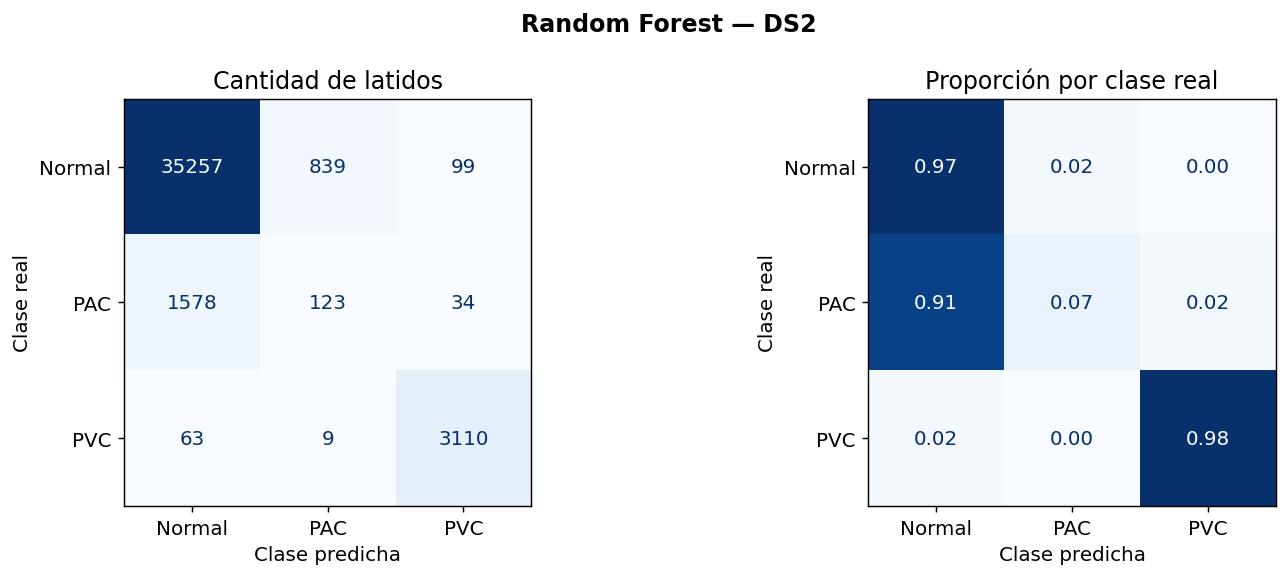

In [27]:
# CELDA 19 - Random Forest (entrenamiento en DS1, evaluación en DS2)
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300,
                            min_samples_leaf=5,
                            class_weight='balanced_subsample',
                            n_jobs=-1,
                            random_state=42)
rf.fit(df_ds1[FEATURES], df_ds1['clase'])

res_rf = reporte(df_ds2['clase'].values, rf.predict(df_ds2[FEATURES]),
                 'Random Forest — DS2', '11_cm_random_forest.png')

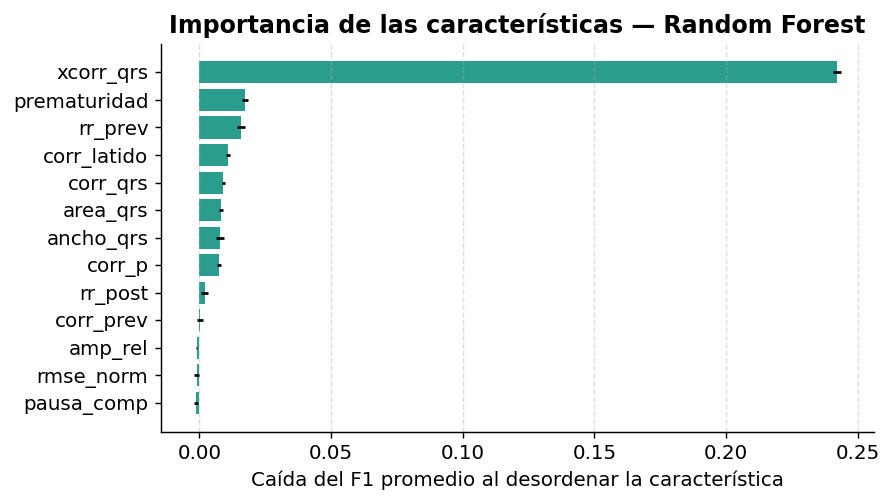

In [29]:
# CELDA 20 - Importancia de las características (permutación sobre DS2)
from sklearn.inspection import permutation_importance

imp = permutation_importance(rf, df_ds2[FEATURES], df_ds2['clase'],
                             scoring='f1_macro', n_repeats=5,
                             random_state=42, n_jobs=-1)
orden = np.argsort(imp.importances_mean)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(np.array(FEATURES)[orden], imp.importances_mean[orden],
        xerr=imp.importances_std[orden], color='#2a9d8f')
ax.set_xlabel('Caída del F1 promedio al desordenar la característica')
ax.set_title('Importancia de las características — Random Forest', fontweight='bold')
ax.grid(axis='x', ls='--', alpha=0.4)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('12_importancia_rf.png', bbox_inches='tight')
plt.show()

In [31]:
# CELDA 21 - Comparación final: reglas vs Random Forest (DS2)

comparacion = pd.concat({'Reglas': res_reglas[['Se', 'Pp', 'F1']],
                         'Random Forest': res_rf[['Se', 'Pp', 'F1']]}, axis=1)
print("Comparación de los dos clasificadores sobre DS2:")
display(comparacion.round(3))

# Resultados paciente por paciente (DS2)
filas = []
for reg, g in df_ds2.groupby('registro'):
    y = g['clase'].values
    p_reglas = clasificar_reglas(g)
    p_rf = rf.predict(g[FEATURES])
    _, _, f1_r, n = precision_recall_fscore_support(y, p_reglas, labels=CLASES, zero_division=0)
    _, _, f1_f, _ = precision_recall_fscore_support(y, p_rf, labels=CLASES, zero_division=0)
    filas.append({
        'Registro': reg,
        'n N': n[0], 'n PAC': n[1], 'n PVC': n[2],
        'F1 PAC reglas': f1_r[1] if n[1] > 0 else np.nan,
        'F1 PAC RF':     f1_f[1] if n[1] > 0 else np.nan,
        'F1 PVC reglas': f1_r[2] if n[2] > 0 else np.nan,
        'F1 PVC RF':     f1_f[2] if n[2] > 0 else np.nan,
        'N→PAC reglas':  int(np.sum((y == 'N') & (p_reglas == 'A'))),
        'N→PVC reglas':  int(np.sum((y == 'N') & (p_reglas == 'V'))),
        'N→PVC RF':      int(np.sum((y == 'N') & (p_rf == 'V'))),
    })

tabla_reg = pd.DataFrame(filas).set_index('Registro')
print("\nResultados por paciente de DS2 (vacío = el paciente no tiene esa clase).")
print("N→PAC / N→PVC = latidos normales clasificados como PAC / PVC.")
display(tabla_reg.round(2))

Comparación de los dos clasificadores sobre DS2:


Reglas               Random Forest              
                     Se     Pp     F1            Se     Pp     F1
Normal            0.870  0.961  0.913         0.974  0.956  0.965
PAC               0.213  0.107  0.142         0.071  0.127  0.091
PVC               0.979  0.639  0.774         0.977  0.959  0.968
Promedio (macro)  0.687  0.569  0.610         0.674  0.680  0.675


Resultados por paciente de DS2 (vacío = el paciente no tiene esa clase).
N→PAC / N→PVC = latidos normales clasificados como PAC / PVC.


,n N,n PAC,n PVC,F1 PAC reglas,F1 PAC RF,F1 PVC reglas,F1 PVC RF,N→PAC reglas,N→PVC reglas,N→PVC RF
Registro,,,,,,,,,,
100,2236,33,1,0.81,0.43,0.07,1.00,15,26,0
103,2074,2,0,0.08,0.67,NaN,NaN,44,4,1
105,2488,0,41,NaN,NaN,0.43,0.44,20,105,74
111,0,0,1,NaN,NaN,1.00,1.00,0,0,0
113,1787,0,0,NaN,NaN,NaN,NaN,291,0,0
117,1532,1,0,0.00,0.00,NaN,NaN,2,651,0
121,1859,1,1,1.00,0.00,0.09,0.40,0,20,3
123,1512,0,3,NaN,NaN,1.00,1.00,255,0,0
200,1735,30,817,0.28,0.62,0.96,0.98,104,37,4


# Conclusión
La detección alcanzó Se = 99,2 % y Pp = 99,7 % en los 44 registros, después de ajustar el período refractario para no eliminar los ectópicos. El análisis estadístico mostró que los PAC se distinguen de los normales por su prematuridad y su onda P, y los PVC por la forma del QRS. El Random Forest clasificó los PVC con un F1 de 0,97, mientras que los PAC fueron la clase más difícil para los dos clasificadores, porque su QRS es igual al normal y la prematuridad falla cuando el ritmo es irregular o hay muchos PAC.